In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28    # Our data has 2 dimensions (x, y coordinates)
NOISE_DIM = 8          # Dimension of noise input to generator
HIDDEN_DIM = 2048      # Size of hidden layers in our neural networks

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Hidden dimension: {HIDDEN_DIM}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Hidden dimension: 2048
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """
    Generator network that creates fake data from random noise.
    
    The Generator takes random noise as input and transforms it into
    data that should look like our real moon-shaped data.
    """
    
    def __init__(self, noise_dim, output_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: noise -> hidden
            nn.Linear(noise_dim, hidden_dim),
            nn.ReLU(),
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            # Output layer: hidden -> data
            nn.Linear(hidden_dim, output_dim),
            # No activation on output - we want raw coordinates
        )
    
    def forward(self, noise):
        """
        Transform noise into fake data.
        
        Args:
            noise: Random noise tensor of shape (batch_size, noise_dim)
        
        Returns:
            fake_data: Generated data of shape (batch_size, output_dim)
        """
        return self.net(noise)


In [6]:
class Discriminator(nn.Module):
    """
    Discriminator network that distinguishes between real and fake data.
    
    The Discriminator takes data (real or fake) as input and outputs
    a probability that the data is real (closer to 1) or fake (closer to 0).
    """
    
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: data -> hidden
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),  # LeakyReLU helps with gradient flow
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),

            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            # Output layer: hidden -> probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()  # Output probability between 0 and 1
        )
    
    def forward(self, data):
        """
        Classify data as real or fake.
        
        Args:
            data: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            probability: Probability that data is real (0-1)
        """
        return self.net(data)


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, INPUT_DIM, HIDDEN_DIM)
discriminator = Discriminator(INPUT_DIM, HIDDEN_DIM)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 10,017,552
Discriminator parameters: 10,002,433
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Linear(in_features=8, out_features=2048, bias=True)
    (1): ReLU()
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): ReLU()
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): ReLU()
    (6): Linear(in_features=2048, out_features=784, bias=True)
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=2048, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=2048, out_features=1, bias=True)
    (7):

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Generated data as numpy array
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate random noise with correct device and dtype
        noise = torch.randn(num_samples, NOISE_DIM, device=device, dtype=torch.float32)
        
        # Generate fake data
        fake_samples = generator(noise)
        
        # Convert to numpy for visualization
        fake_samples = fake_samples.cpu().numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.377491	G_loss: 0.696481
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.399579	G_loss: 0.659629
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.392515	G_loss: 0.816766
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.385410	G_loss: 0.771187
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.351154	G_loss: 0.732097
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.242065	G_loss: 0.896350
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.397122	G_loss: 0.877649
Epoch: 1 [44800/60000 (75%)]	D_loss: 0.960580	G_loss: 1.358338
Epoch: 1 [51200/60000 (85%)]	D_loss: 0.149960	G_loss: 4.514286
Epoch: 1 [57600/60000 (96%)]	D_loss: 0.428517	G_loss: 3.257611
====> Epoch: 1 Train D_loss: 1.2018, Train G_loss: 2.0922
====> Epoch: 1 Val D_loss: 0.2571, Val G_loss: 2.8302
📈 Epoch 1 Summary:
   Train D Loss: 1.2018, Val D Loss: 0.2571
   Train G Loss: 2.0922, Val G Loss: 2.8302

📊 Epoch 2/100
------------------------

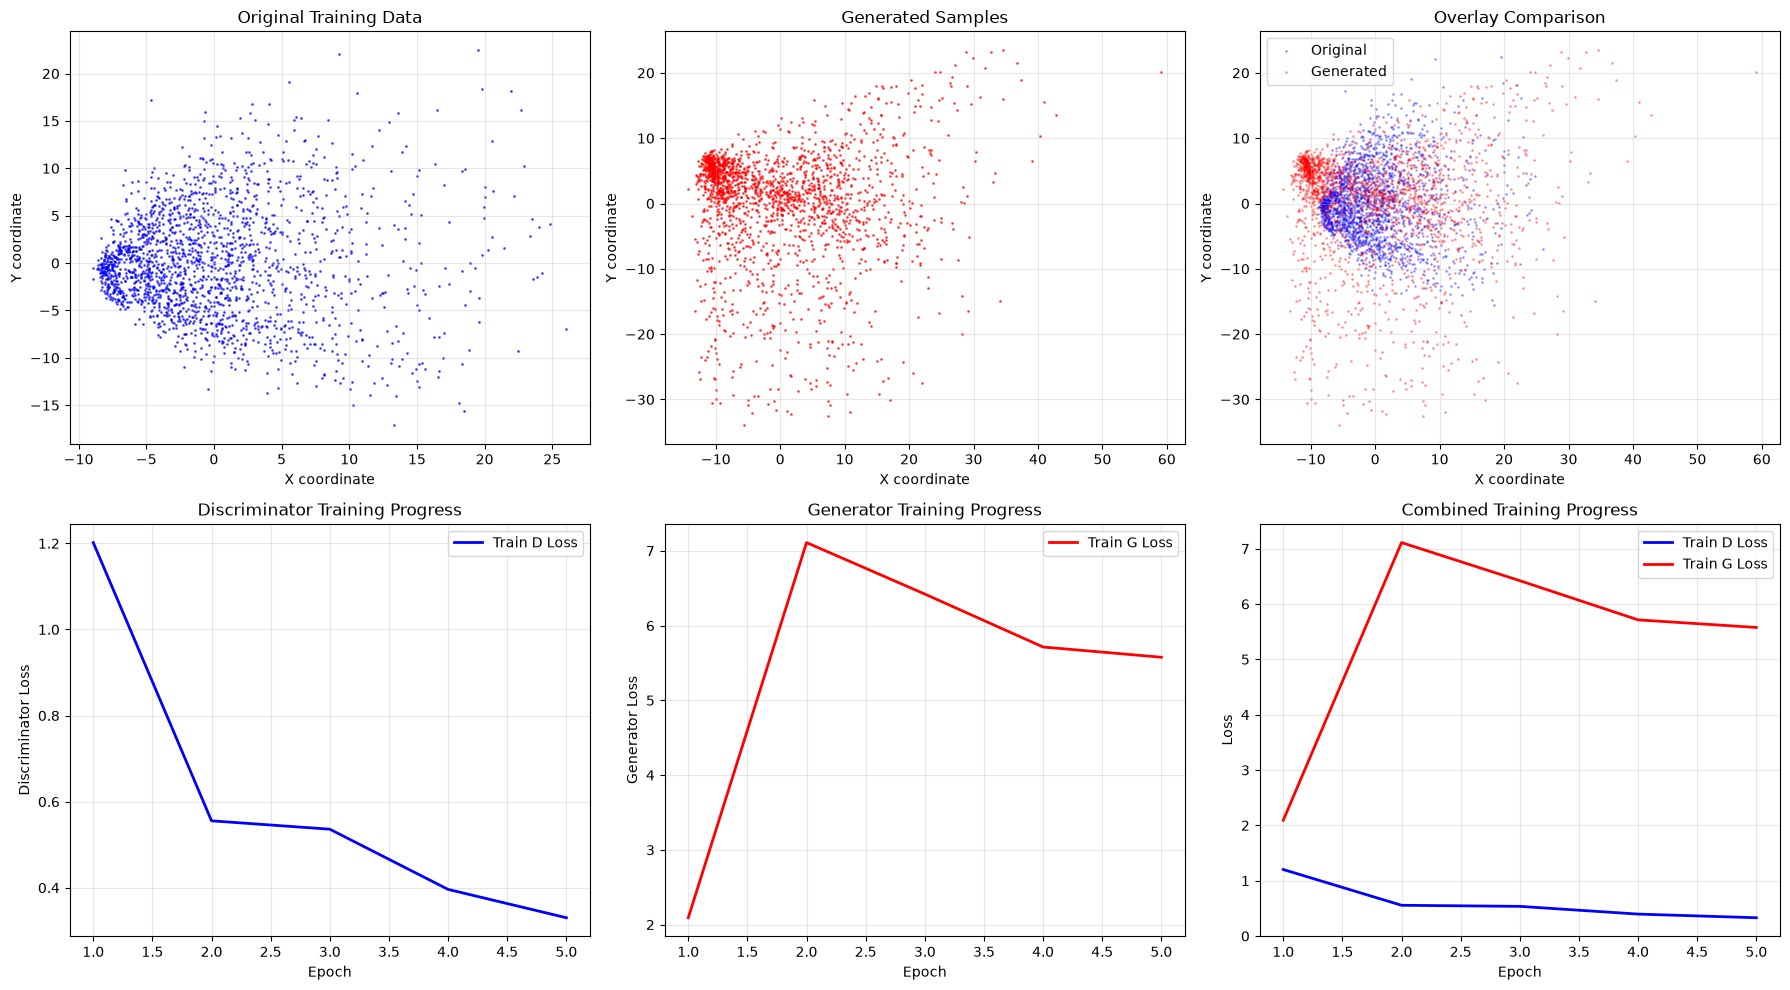

📈 Epoch 5 Summary:
   Train D Loss: 0.3303, Val D Loss: 0.2743
   Train G Loss: 5.5763, Val G Loss: 3.2919

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 0.302743	G_loss: 3.882885
Epoch: 6 [6400/60000 (11%)]	D_loss: 0.510966	G_loss: 7.601599
Epoch: 6 [12800/60000 (21%)]	D_loss: 0.271571	G_loss: 3.879888
Epoch: 6 [19200/60000 (32%)]	D_loss: 0.330392	G_loss: 4.502804
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.031690	G_loss: 3.194685
Epoch: 6 [32000/60000 (53%)]	D_loss: 0.143417	G_loss: 2.904377
Epoch: 6 [38400/60000 (64%)]	D_loss: 0.229186	G_loss: 6.400221
Epoch: 6 [44800/60000 (75%)]	D_loss: 0.196062	G_loss: 3.650850
Epoch: 6 [51200/60000 (85%)]	D_loss: 0.073184	G_loss: 5.263578
Epoch: 6 [57600/60000 (96%)]	D_loss: 0.279359	G_loss: 5.529364
====> Epoch: 6 Train D_loss: 0.3132, Train G_loss: 5.2265
====> Epoch: 6 Val D_loss: 0.1266, Val G_loss: 4.5486
📈 Epoch 6 Summary:
   Train D Loss: 0.3132, Val D Loss: 0.1266
   Train G Loss: 5.2265, Val G Loss: 4

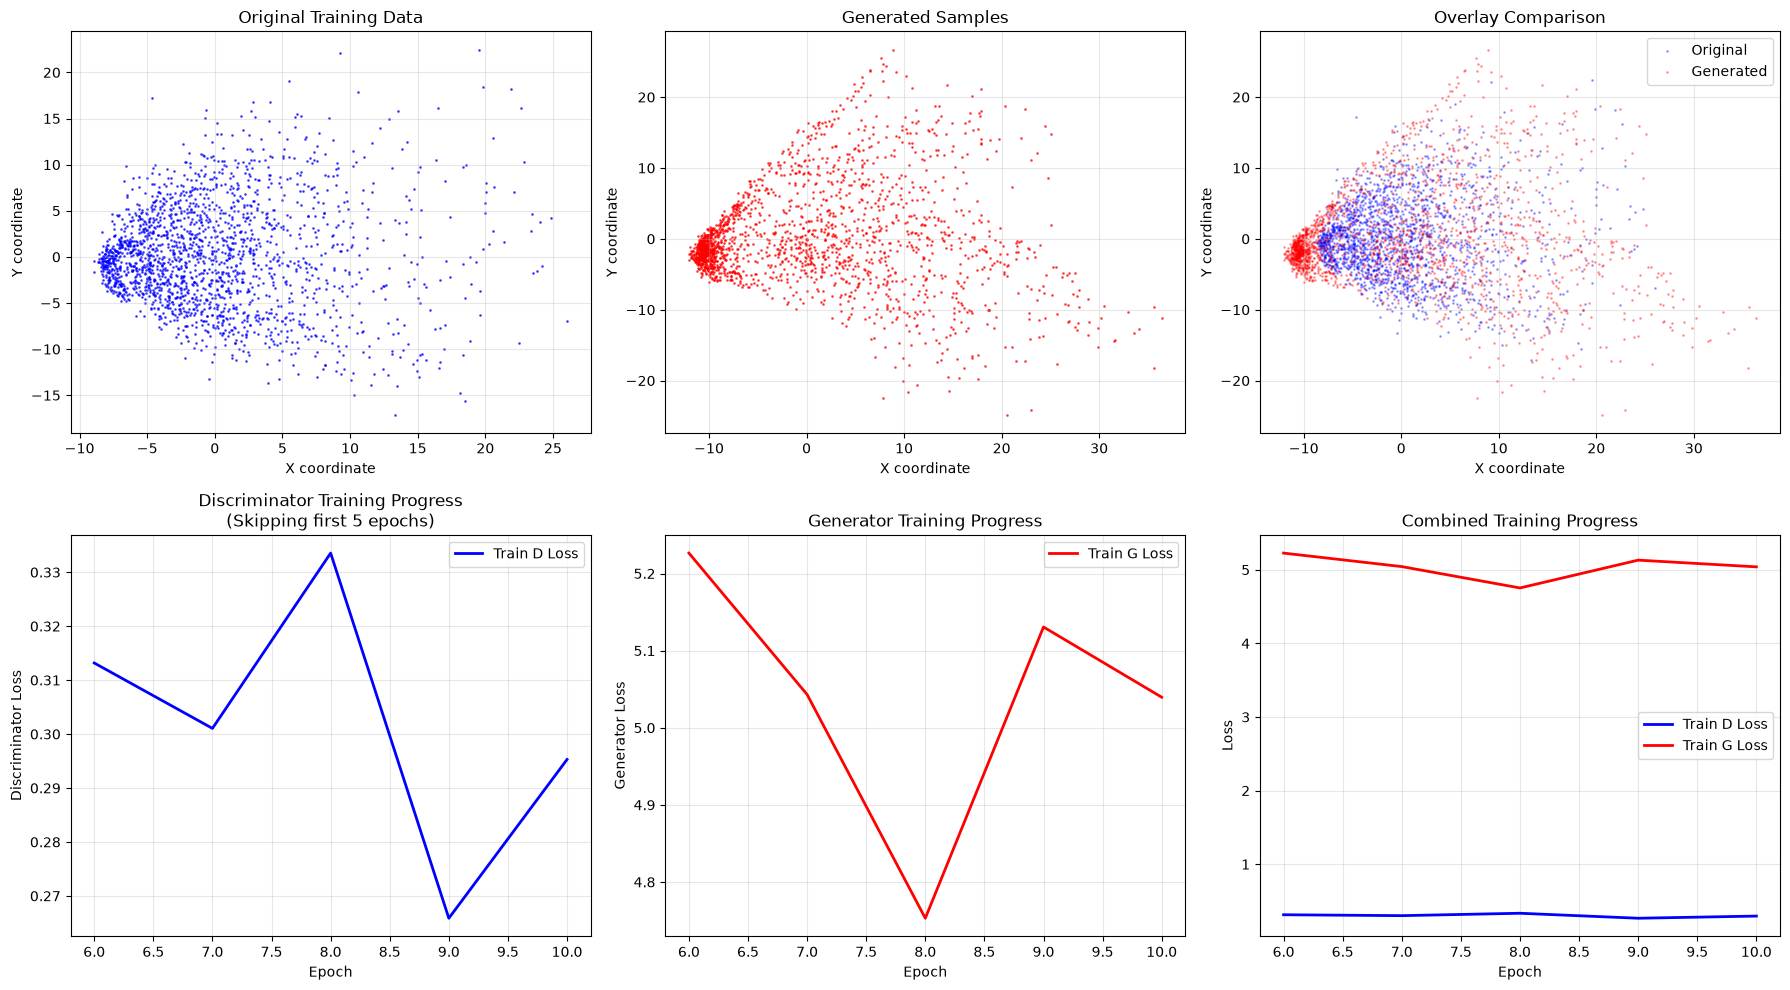

📈 Epoch 10 Summary:
   Train D Loss: 0.2953, Val D Loss: 0.1762
   Train G Loss: 5.0396, Val G Loss: 4.2539

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 0.149410	G_loss: 4.297916
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.041343	G_loss: 5.389343
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.230198	G_loss: 8.120905
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.143446	G_loss: 4.448307
Epoch: 11 [25600/60000 (43%)]	D_loss: 0.195612	G_loss: 4.990791
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.260102	G_loss: 3.122806
Epoch: 11 [38400/60000 (64%)]	D_loss: 0.119229	G_loss: 4.657810
Epoch: 11 [44800/60000 (75%)]	D_loss: 0.349506	G_loss: 7.914860
Epoch: 11 [51200/60000 (85%)]	D_loss: 0.127901	G_loss: 4.617972
Epoch: 11 [57600/60000 (96%)]	D_loss: 2.409843	G_loss: 5.351599
====> Epoch: 11 Train D_loss: 0.2915, Train G_loss: 5.0790
====> Epoch: 11 Val D_loss: 0.2305, Val G_loss: 3.7138
📈 Epoch 11 Summary:
   Train D Loss: 0.2915, Val D Loss: 0.2305
   Train G Loss: 5.0790

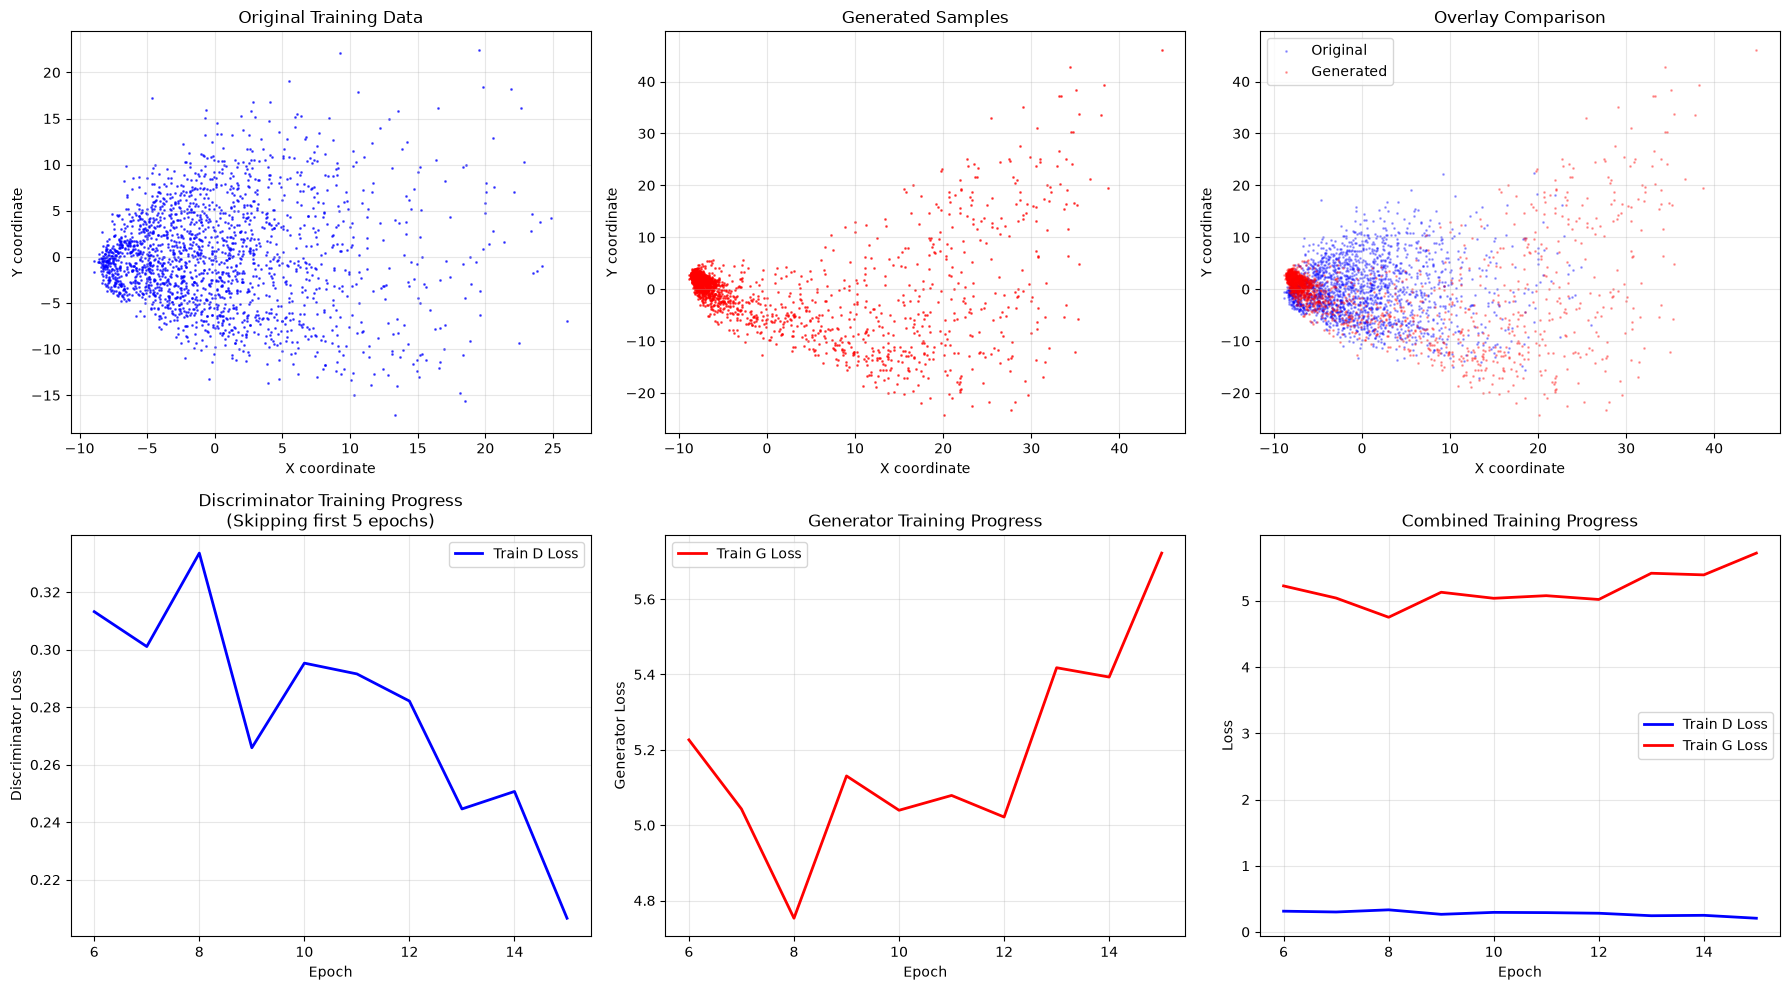

📈 Epoch 15 Summary:
   Train D Loss: 0.2066, Val D Loss: 0.2869
   Train G Loss: 5.7222, Val G Loss: 2.8813

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.291186	G_loss: 5.117156
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.093026	G_loss: 4.970488
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.097014	G_loss: 6.249786
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.379196	G_loss: 6.756998
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.162104	G_loss: 5.097438
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.087015	G_loss: 5.961533
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.377705	G_loss: 3.076027
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.199795	G_loss: 3.894869
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.142632	G_loss: 4.134122
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.348729	G_loss: 9.609578
====> Epoch: 16 Train D_loss: 0.2040, Train G_loss: 5.8974
====> Epoch: 16 Val D_loss: 0.1845, Val G_loss: 4.0846
📈 Epoch 16 Summary:
   Train D Loss: 0.2040, Val D Loss: 0.1845
   Train G Loss: 5.8974

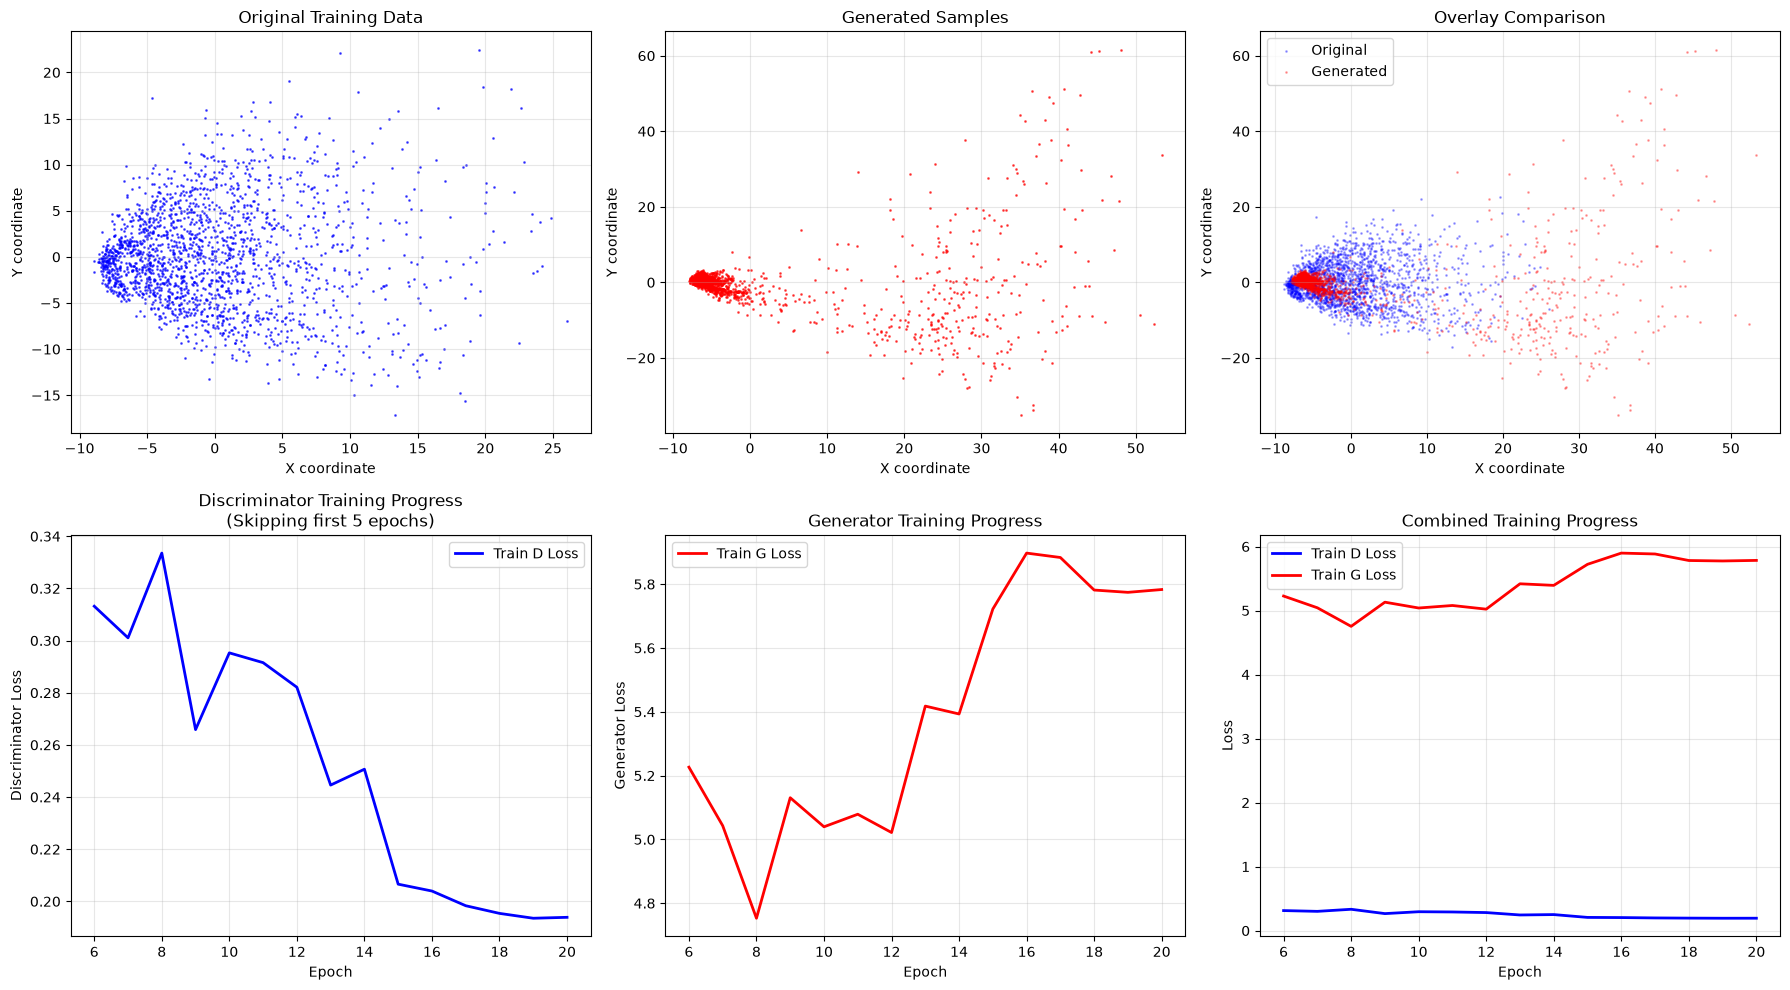

📈 Epoch 20 Summary:
   Train D Loss: 0.1939, Val D Loss: 0.2781
   Train G Loss: 5.7832, Val G Loss: 3.5361

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.179277	G_loss: 4.327072
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.212951	G_loss: 5.661850
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.202605	G_loss: 6.313576
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.088735	G_loss: 7.233564
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.176440	G_loss: 5.976641
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.117105	G_loss: 4.904641
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.157506	G_loss: 4.702892
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.142547	G_loss: 3.965932
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.199745	G_loss: 7.915109
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.265450	G_loss: 5.065816
====> Epoch: 21 Train D_loss: 0.1694, Train G_loss: 6.0284
====> Epoch: 21 Val D_loss: 0.1959, Val G_loss: 3.2866
📈 Epoch 21 Summary:
   Train D Loss: 0.1694, Val D Loss: 0.1959
   Train G Loss: 6.0284

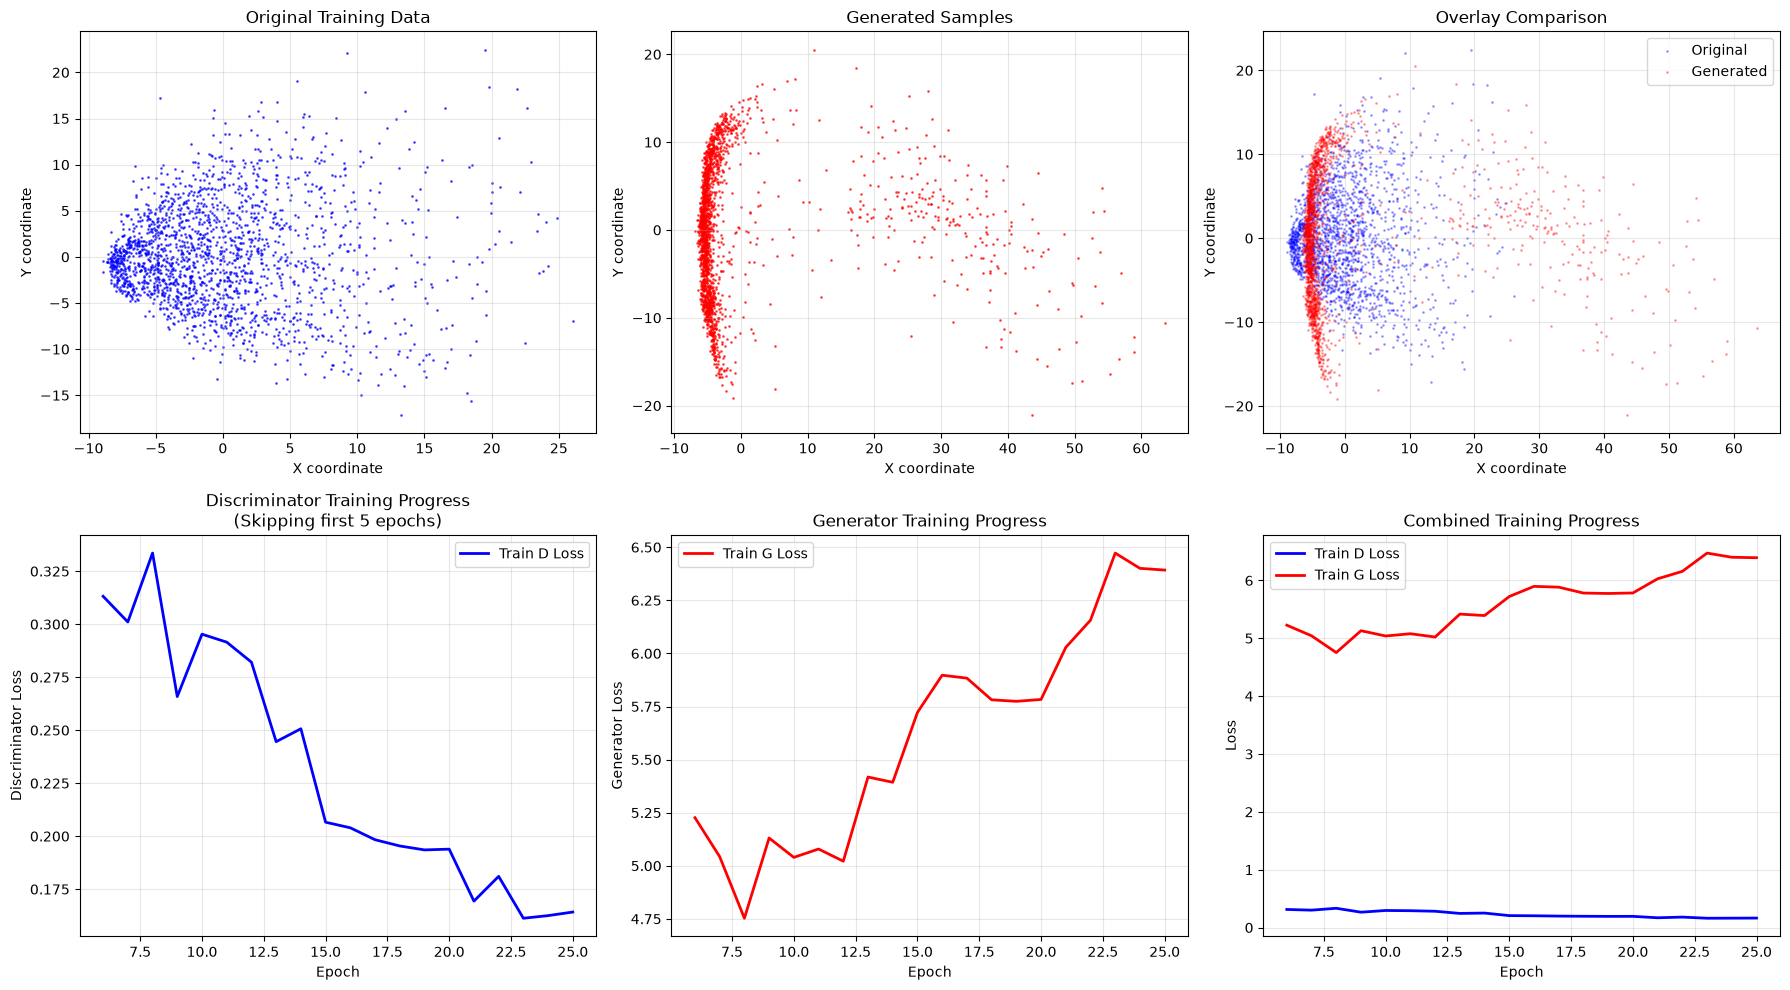

📈 Epoch 25 Summary:
   Train D Loss: 0.1642, Val D Loss: 0.1167
   Train G Loss: 6.3925, Val G Loss: 7.1275

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.058680	G_loss: 7.699196
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.174802	G_loss: 4.913762
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.094512	G_loss: 9.445128
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.188404	G_loss: 4.320134
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.149358	G_loss: 5.509297
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.107587	G_loss: 5.953939
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.096226	G_loss: 4.028134
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.121514	G_loss: 7.312045
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.197487	G_loss: 4.204679
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.060646	G_loss: 6.749364
====> Epoch: 26 Train D_loss: 0.1559, Train G_loss: 6.5371
====> Epoch: 26 Val D_loss: 0.1467, Val G_loss: 6.8707
📈 Epoch 26 Summary:
   Train D Loss: 0.1559, Val D Loss: 0.1467
   Train G Loss: 6.5371

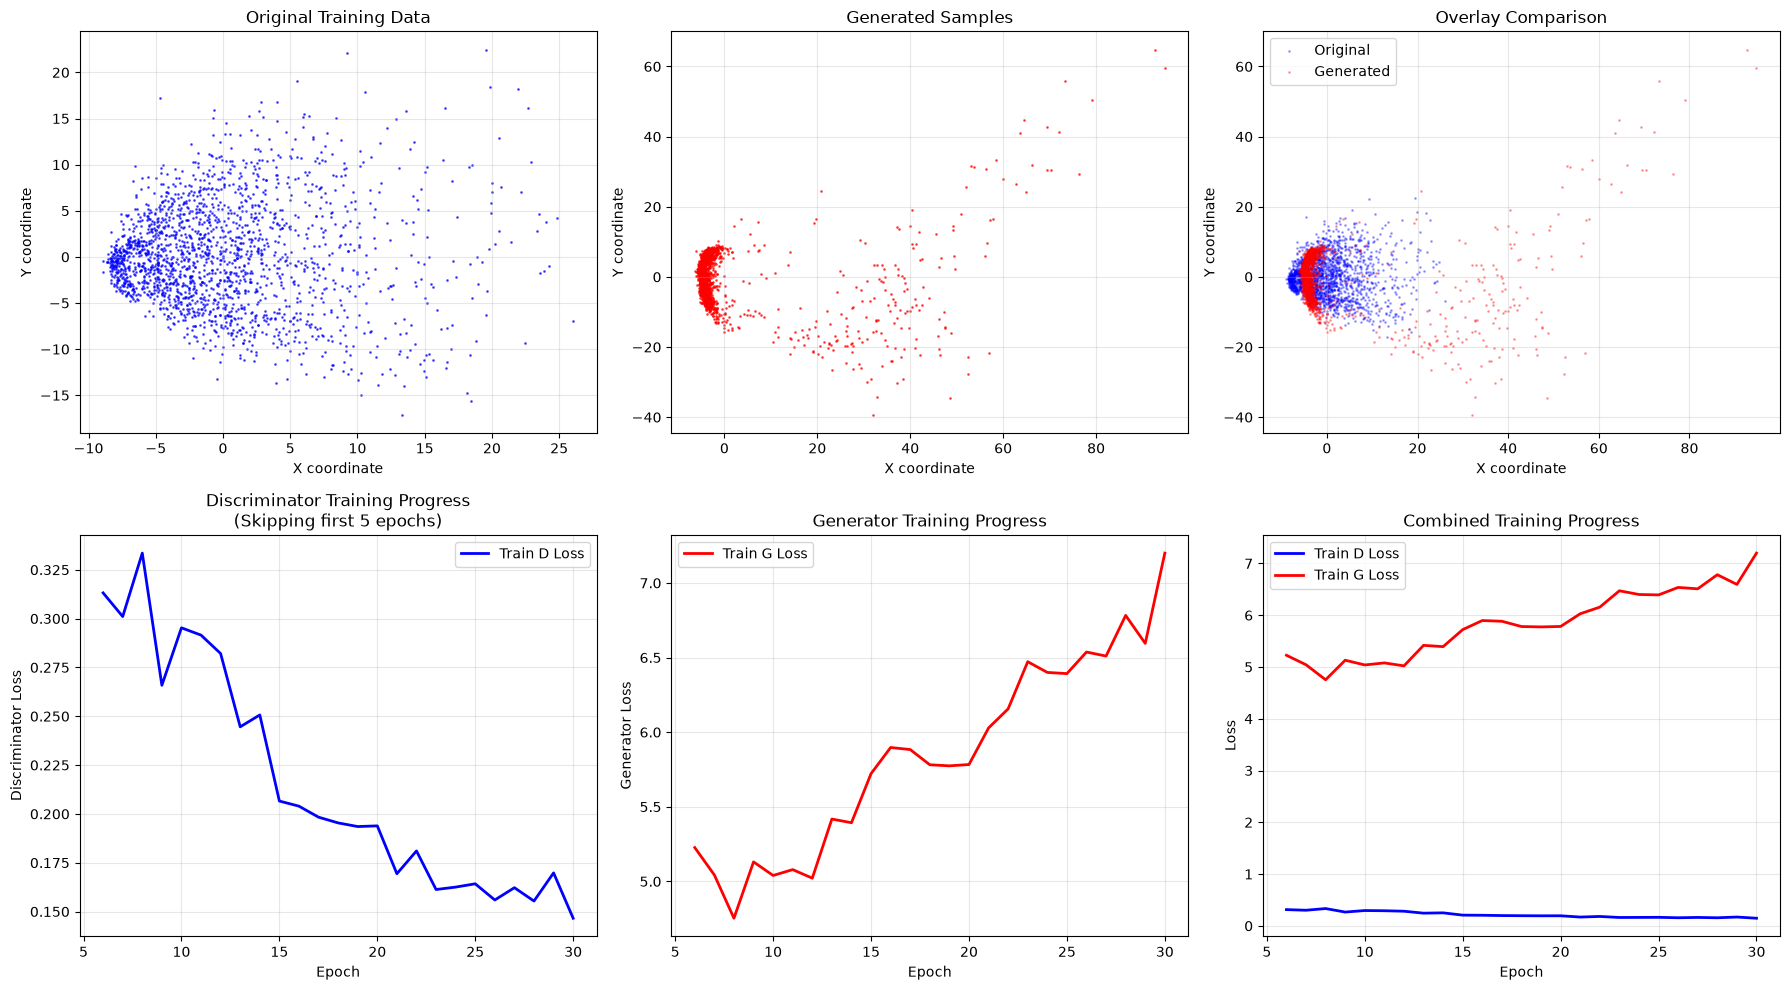

📈 Epoch 30 Summary:
   Train D Loss: 0.1466, Val D Loss: 0.1505
   Train G Loss: 7.2003, Val G Loss: 4.7249

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.127675	G_loss: 5.803268
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.171715	G_loss: 5.607133
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.071224	G_loss: 5.173189
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.086591	G_loss: 6.626680
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.175451	G_loss: 3.885233
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.080884	G_loss: 5.843406
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.167914	G_loss: 4.533587
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.054860	G_loss: 6.232935
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.130527	G_loss: 8.437654
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.040290	G_loss: 7.398757
====> Epoch: 31 Train D_loss: 0.1471, Train G_loss: 7.3777
====> Epoch: 31 Val D_loss: 0.0877, Val G_loss: 7.9634
📈 Epoch 31 Summary:
   Train D Loss: 0.1471, Val D Loss: 0.0877
   Train G Loss: 7.3777

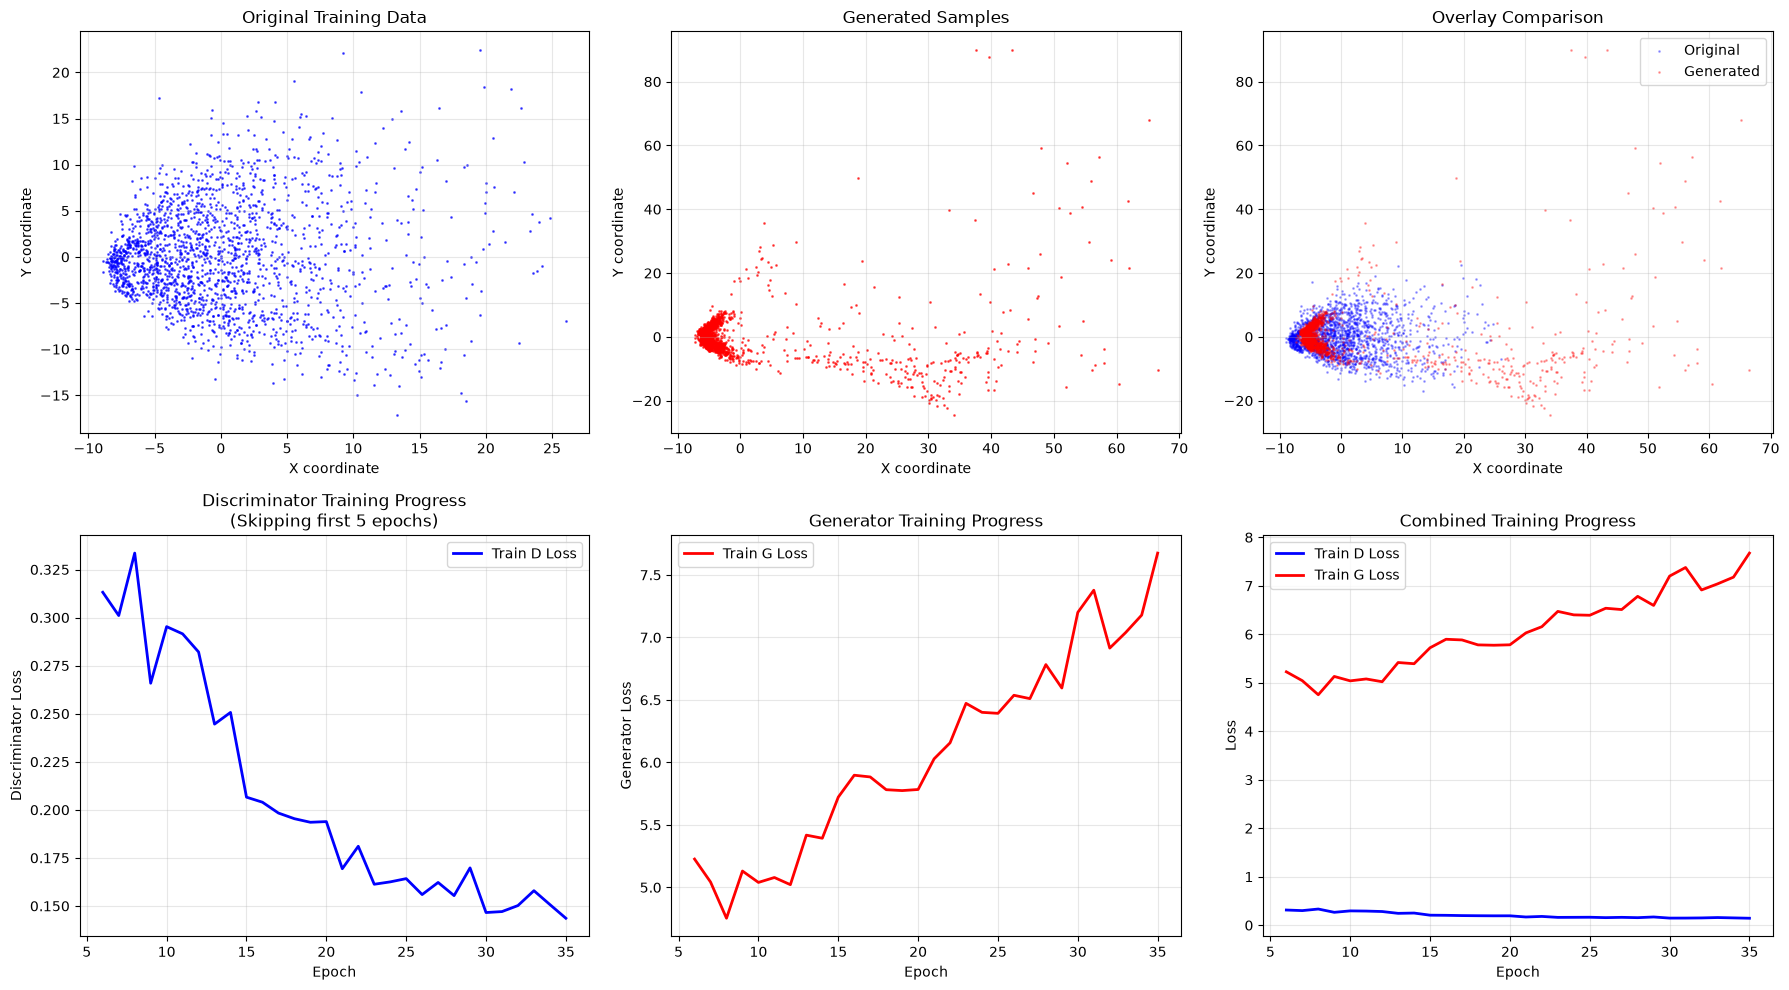

📈 Epoch 35 Summary:
   Train D Loss: 0.1436, Val D Loss: 0.1329
   Train G Loss: 7.6747, Val G Loss: 4.8882

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.086933	G_loss: 5.806897
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.057644	G_loss: 7.427484
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.034431	G_loss: 7.544086
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.115966	G_loss: 7.247100
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.115767	G_loss: 7.277930
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.071672	G_loss: 8.407879
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.181542	G_loss: 3.690307
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.322963	G_loss: 8.819807
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.156079	G_loss: 5.214197
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.226849	G_loss: 5.611393
====> Epoch: 36 Train D_loss: 0.1490, Train G_loss: 7.3777
====> Epoch: 36 Val D_loss: 0.2580, Val G_loss: 5.4947
📈 Epoch 36 Summary:
   Train D Loss: 0.1490, Val D Loss: 0.2580
   Train G Loss: 7.3777

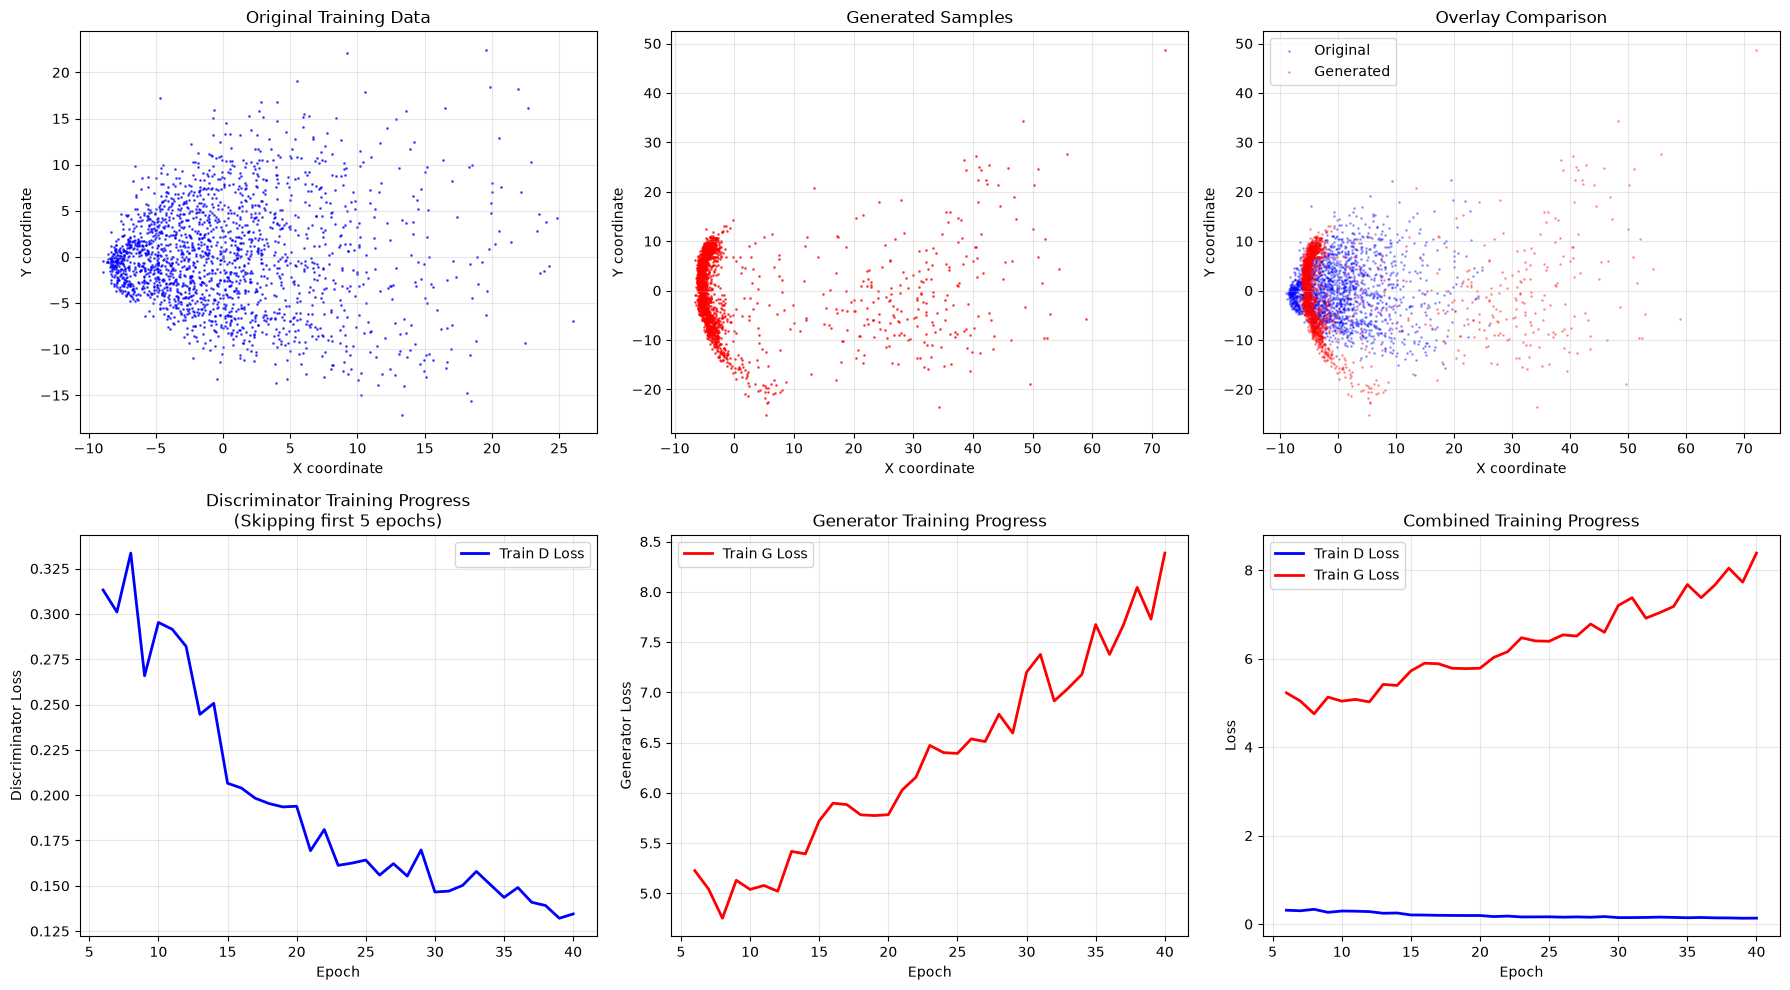

📈 Epoch 40 Summary:
   Train D Loss: 0.1345, Val D Loss: 0.1760
   Train G Loss: 8.3855, Val G Loss: 10.1000

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.145290	G_loss: 10.367958
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.107012	G_loss: 5.920863
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.088694	G_loss: 9.944326
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.126598	G_loss: 7.427642
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.061841	G_loss: 6.891359
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.183109	G_loss: 8.708337
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.116701	G_loss: 6.645889
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.051343	G_loss: 6.124373
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.180853	G_loss: 8.756134
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.180557	G_loss: 6.008730
====> Epoch: 41 Train D_loss: 0.1373, Train G_loss: 7.5764
====> Epoch: 41 Val D_loss: 0.1119, Val G_loss: 11.9878
📈 Epoch 41 Summary:
   Train D Loss: 0.1373, Val D Loss: 0.1119
   Train G Loss: 7.5

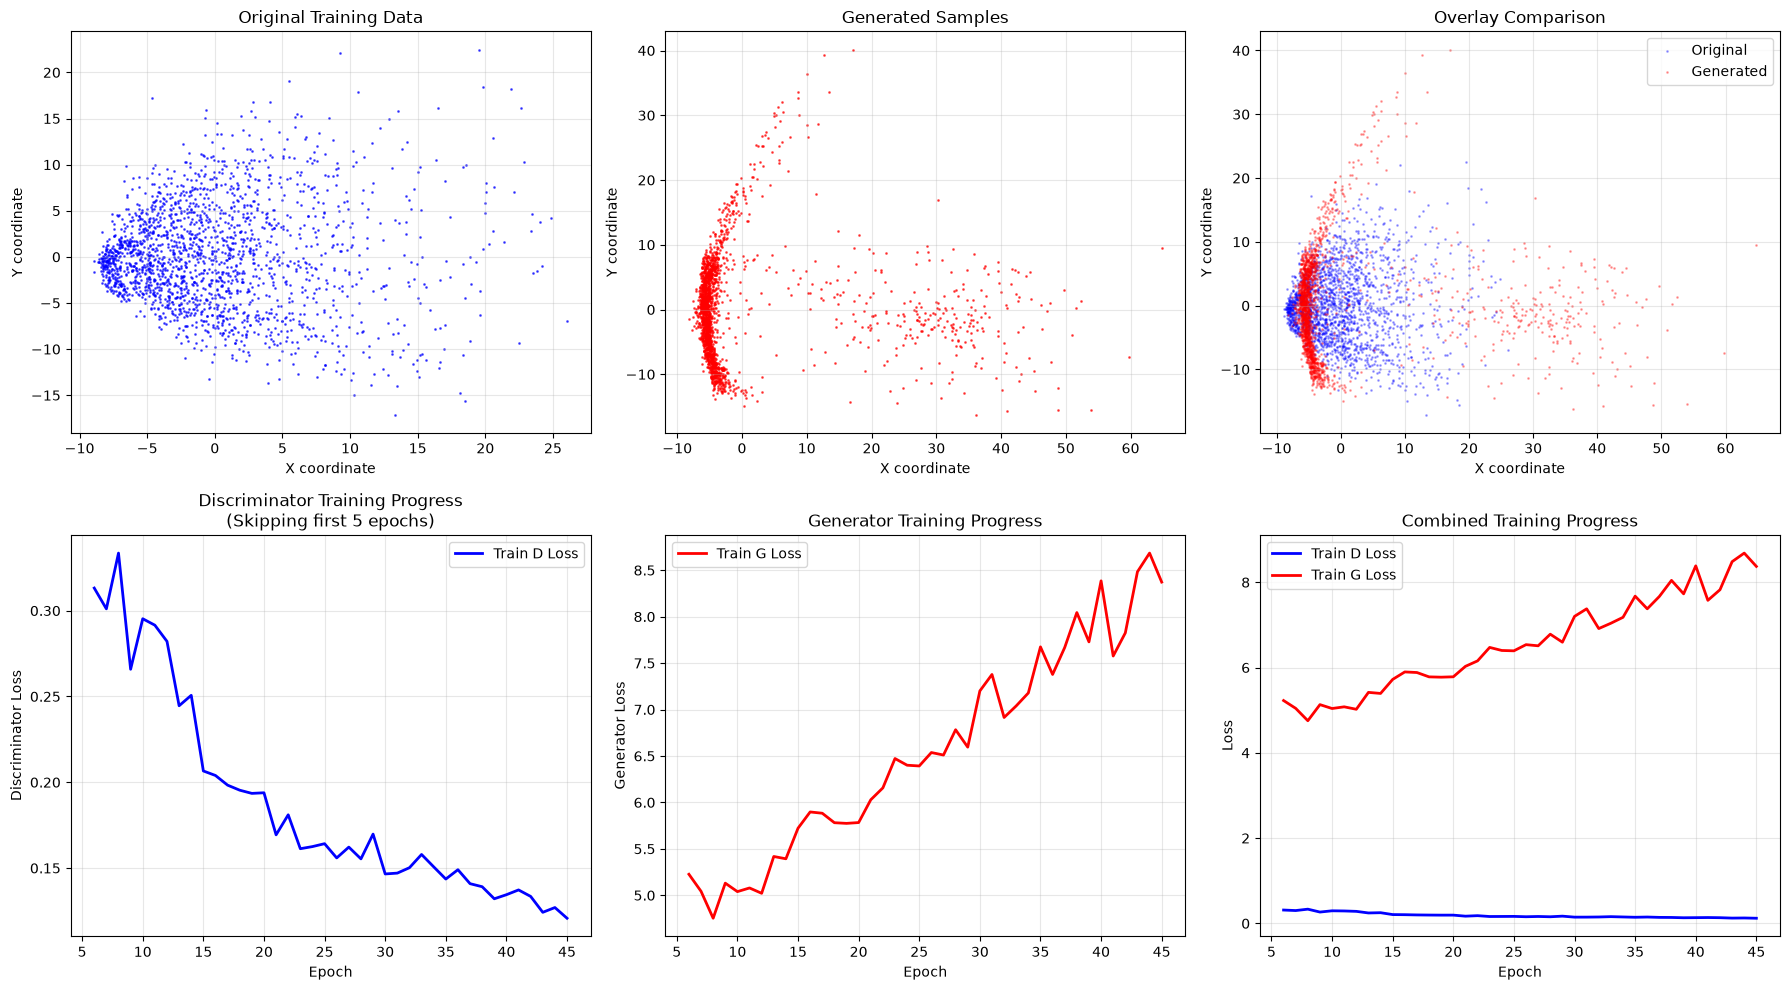

📈 Epoch 45 Summary:
   Train D Loss: 0.1208, Val D Loss: 0.1732
   Train G Loss: 8.3724, Val G Loss: 4.7559

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.155411	G_loss: 4.295744
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.214203	G_loss: 3.762247
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.104183	G_loss: 5.504438
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.082963	G_loss: 16.078949
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.102938	G_loss: 5.353521
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.102058	G_loss: 8.123617
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.115858	G_loss: 7.634703
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.037661	G_loss: 10.408354
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.091312	G_loss: 6.805875
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.319012	G_loss: 8.355740
====> Epoch: 46 Train D_loss: 0.1229, Train G_loss: 8.5311
====> Epoch: 46 Val D_loss: 0.2051, Val G_loss: 3.7695
📈 Epoch 46 Summary:
   Train D Loss: 0.1229, Val D Loss: 0.2051
   Train G Loss: 8.53

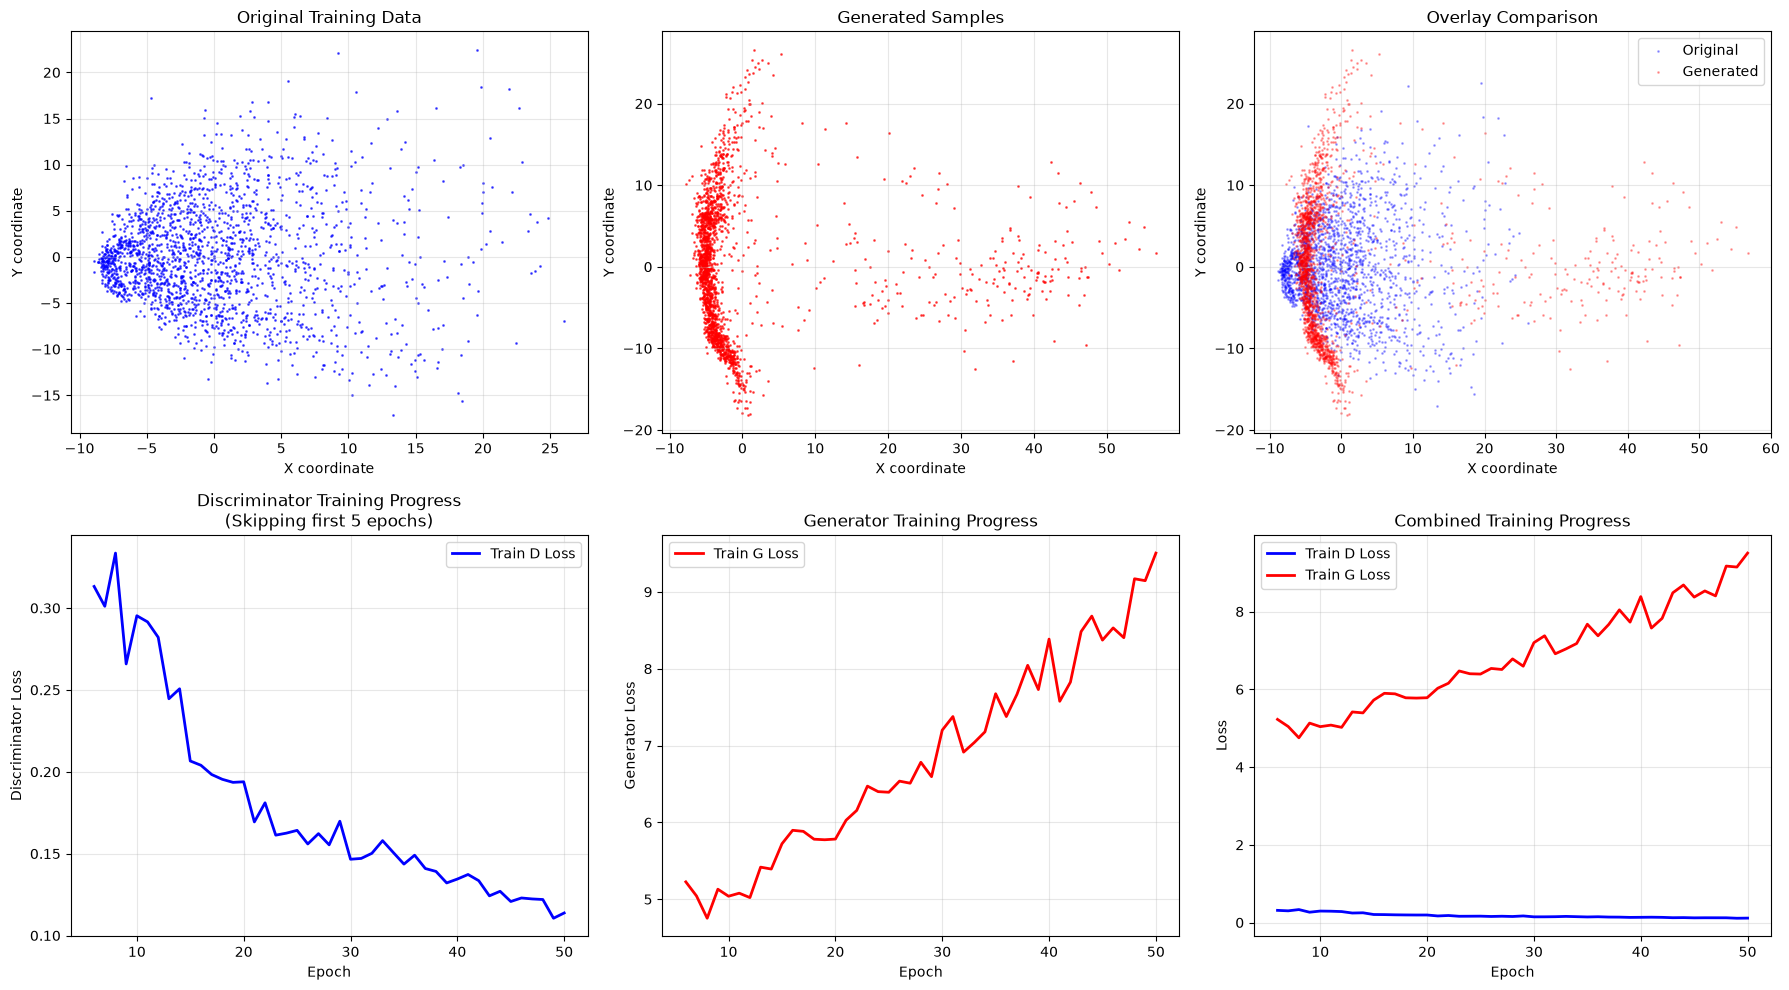

📈 Epoch 50 Summary:
   Train D Loss: 0.1138, Val D Loss: 0.0894
   Train G Loss: 9.5046, Val G Loss: 9.9461

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.046337	G_loss: 8.684858
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.053280	G_loss: 6.527596
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.872306	G_loss: 12.149092
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.088301	G_loss: 5.151018
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.117961	G_loss: 5.268260
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.076532	G_loss: 9.257751
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.060267	G_loss: 9.834879
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.106853	G_loss: 5.242988
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.161441	G_loss: 14.707047
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.173838	G_loss: 7.439101
====> Epoch: 51 Train D_loss: 0.1095, Train G_loss: 9.1959
====> Epoch: 51 Val D_loss: 0.1235, Val G_loss: 7.6887
📈 Epoch 51 Summary:
   Train D Loss: 0.1095, Val D Loss: 0.1235
   Train G Loss: 9.19

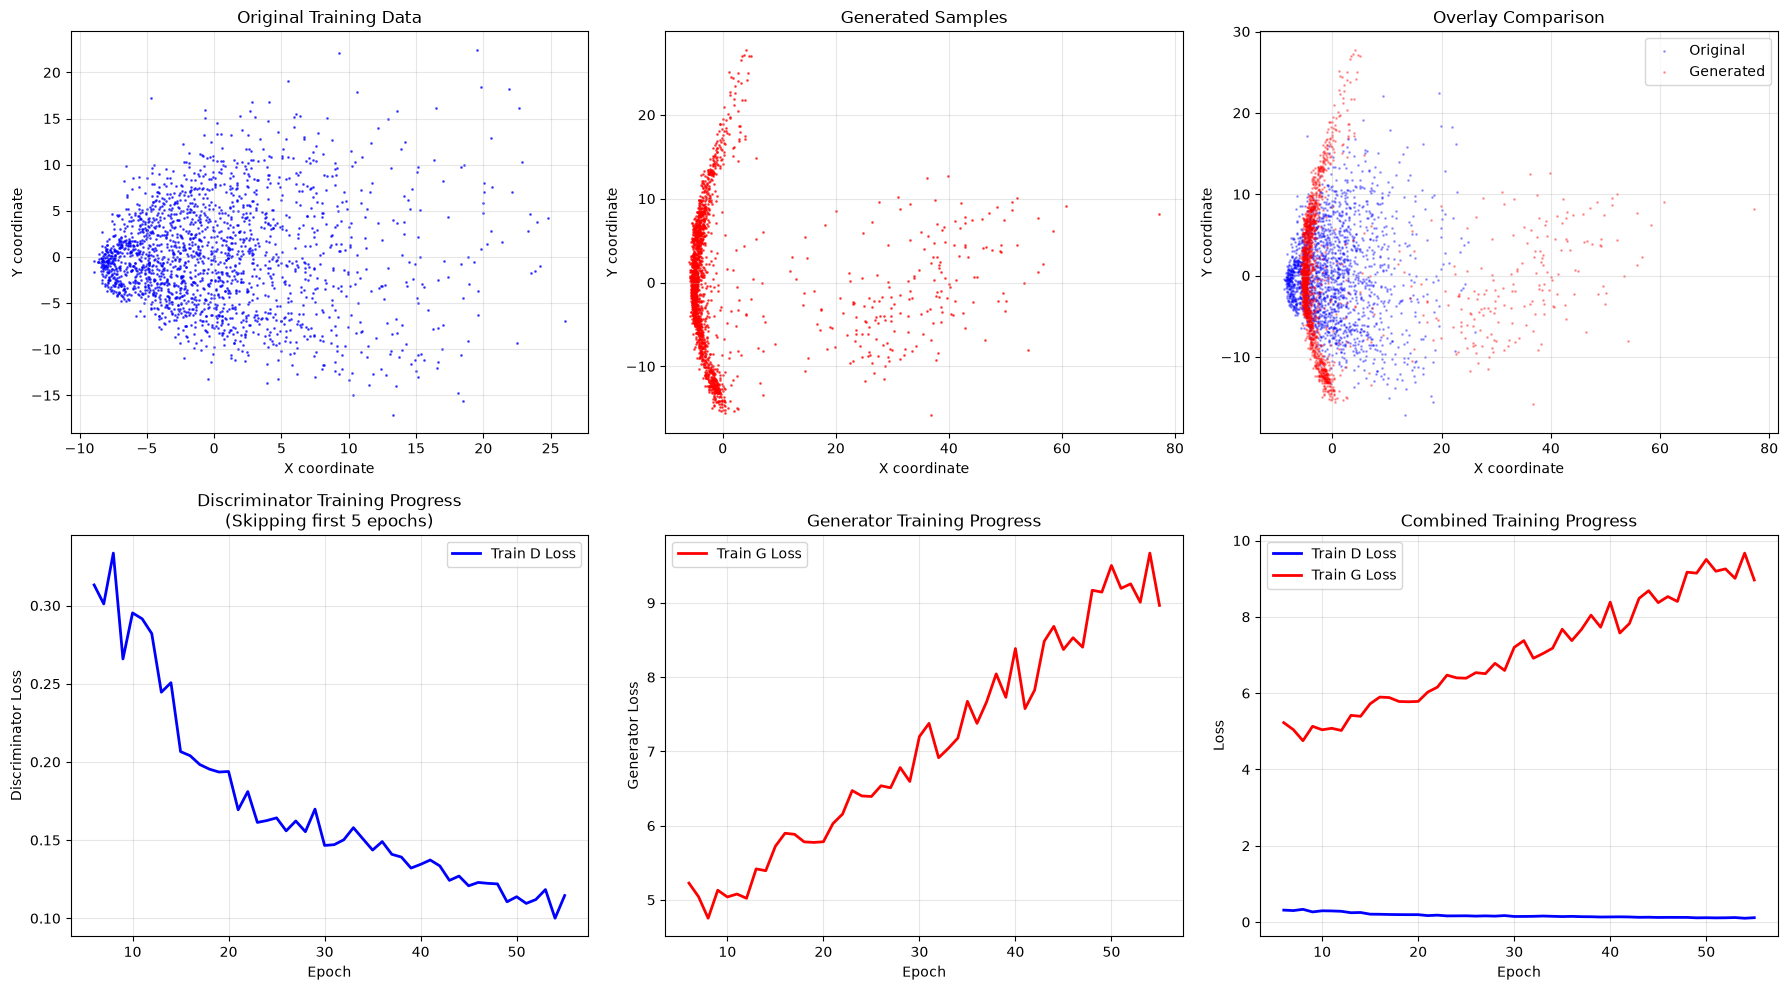

📈 Epoch 55 Summary:
   Train D Loss: 0.1145, Val D Loss: 0.1649
   Train G Loss: 8.9663, Val G Loss: 5.7514

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.091756	G_loss: 4.788174
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.104532	G_loss: 6.276065
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.058711	G_loss: 10.681282
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.085336	G_loss: 7.529433
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.022852	G_loss: 9.336308
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.165949	G_loss: 8.398280
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.180148	G_loss: 7.541141
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.035868	G_loss: 10.509909
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.068011	G_loss: 14.788750
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.239984	G_loss: 10.444906
====> Epoch: 56 Train D_loss: 0.0973, Train G_loss: 9.7183
====> Epoch: 56 Val D_loss: 0.1675, Val G_loss: 5.1378
📈 Epoch 56 Summary:
   Train D Loss: 0.0973, Val D Loss: 0.1675
   Train G Loss: 9.

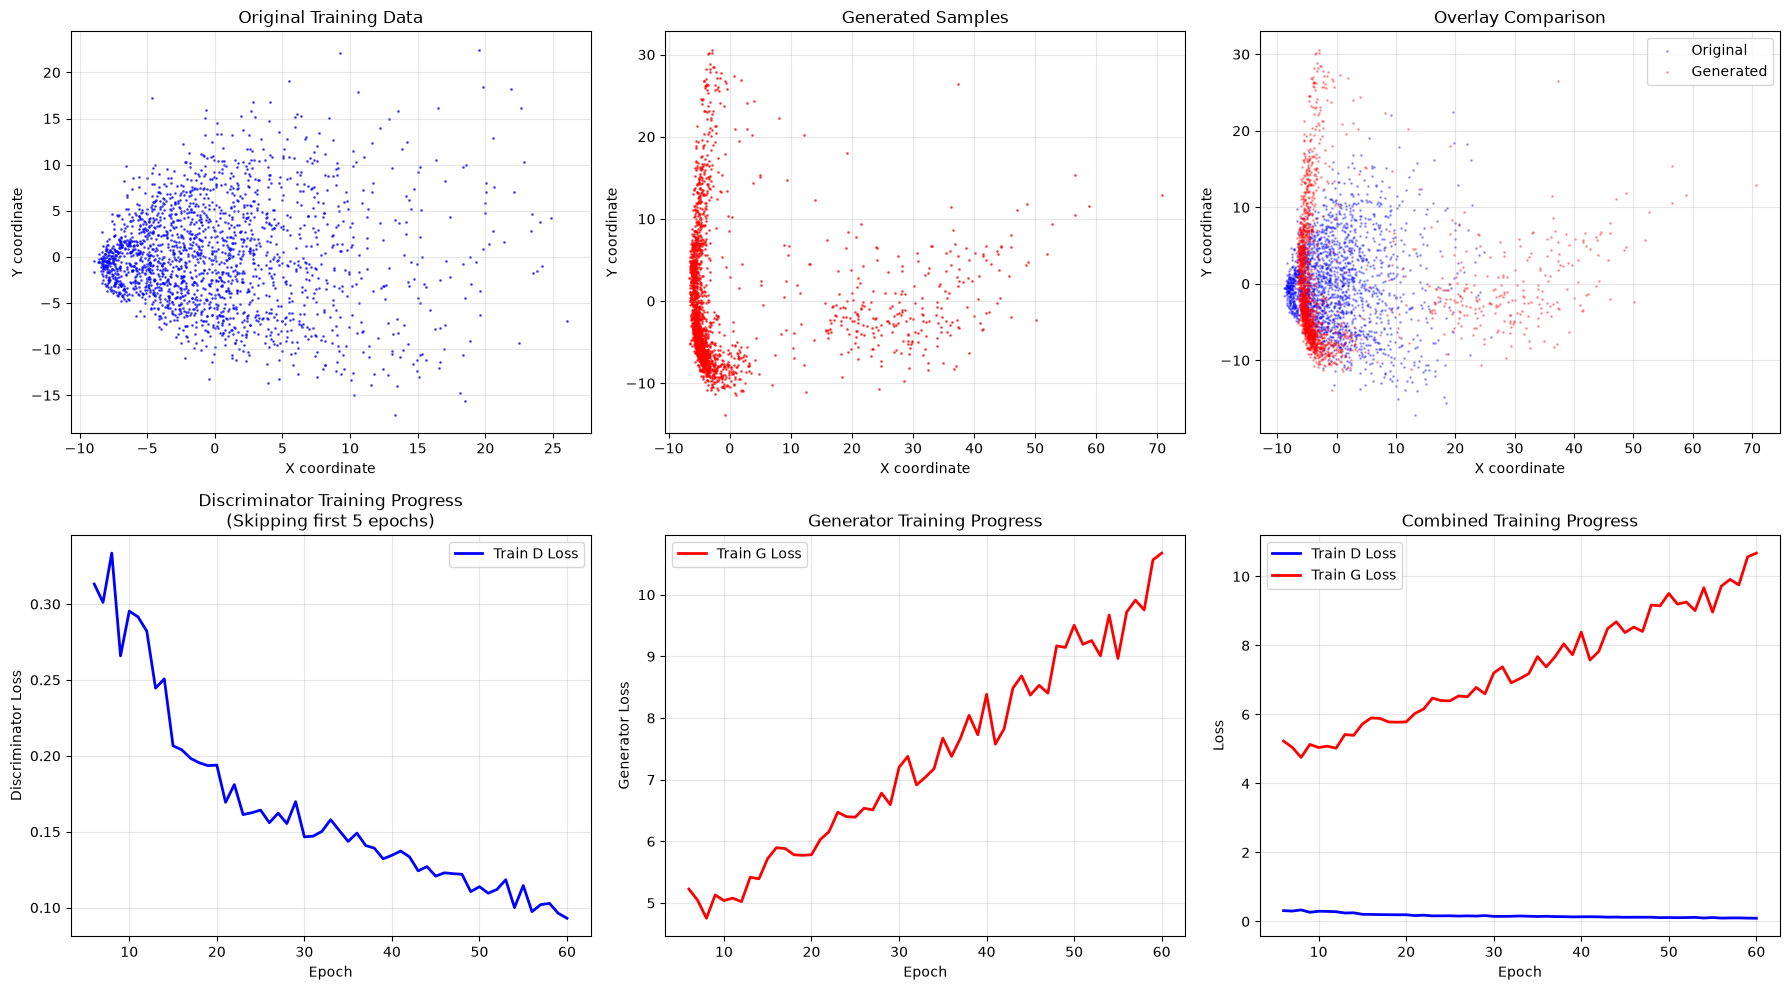

📈 Epoch 60 Summary:
   Train D Loss: 0.0930, Val D Loss: 0.0829
   Train G Loss: 10.6752, Val G Loss: 9.8548

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.022163	G_loss: 9.927596
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.028178	G_loss: 15.879309
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.067291	G_loss: 6.476321
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.087218	G_loss: 11.407939
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.071635	G_loss: 13.570102
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.037103	G_loss: 7.608379
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.033191	G_loss: 11.617182
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.107733	G_loss: 8.808109
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.071784	G_loss: 13.350389
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.061428	G_loss: 11.414984
====> Epoch: 61 Train D_loss: 0.0903, Train G_loss: 10.6874
====> Epoch: 61 Val D_loss: 0.0412, Val G_loss: 12.7799
📈 Epoch 61 Summary:
   Train D Loss: 0.0903, Val D Loss: 0.0412
   Train G Los

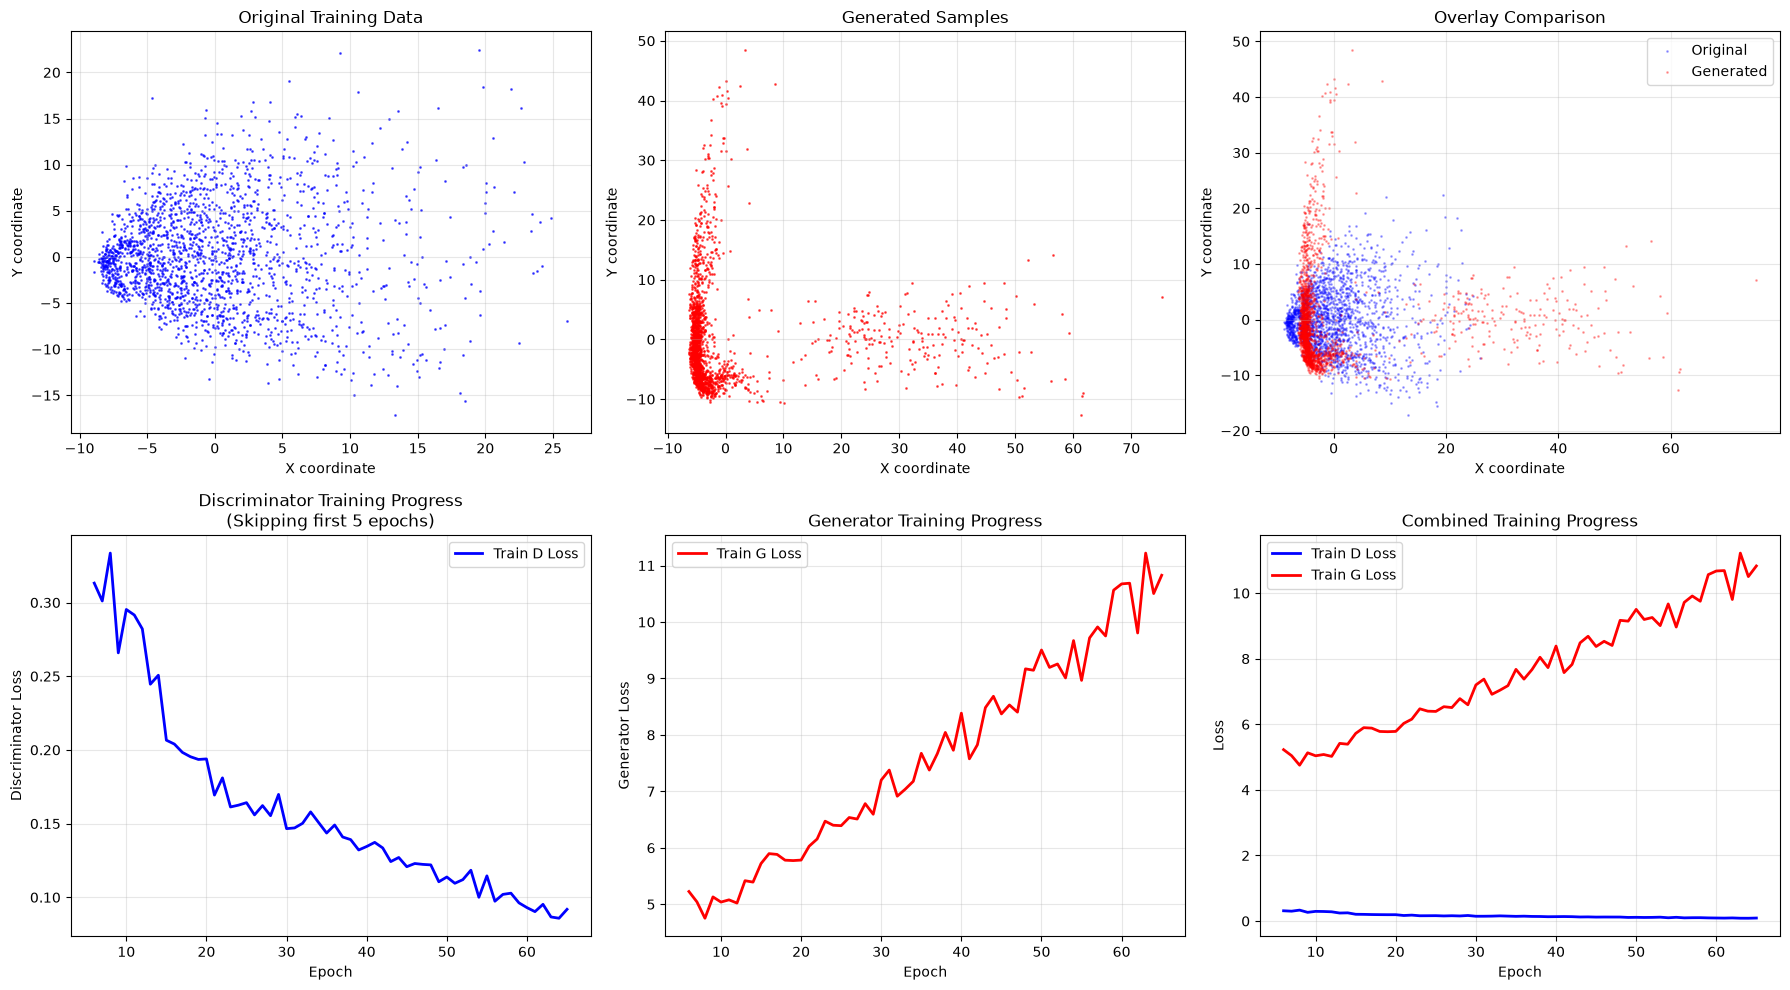

📈 Epoch 65 Summary:
   Train D Loss: 0.0918, Val D Loss: 0.0466
   Train G Loss: 10.8283, Val G Loss: 16.5001

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.018461	G_loss: 16.776346
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.117726	G_loss: 13.886095
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.207165	G_loss: 12.082998
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.119193	G_loss: 6.054045
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.003764	G_loss: 17.563656
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.043215	G_loss: 10.058015
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.043140	G_loss: 16.148899
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.045319	G_loss: 12.297432
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.056760	G_loss: 8.810627
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.070108	G_loss: 8.704476
====> Epoch: 66 Train D_loss: 0.0756, Train G_loss: 11.1401
====> Epoch: 66 Val D_loss: 0.0796, Val G_loss: 8.9484
📈 Epoch 66 Summary:
   Train D Loss: 0.0756, Val D Loss: 0.0796
   Train G Lo

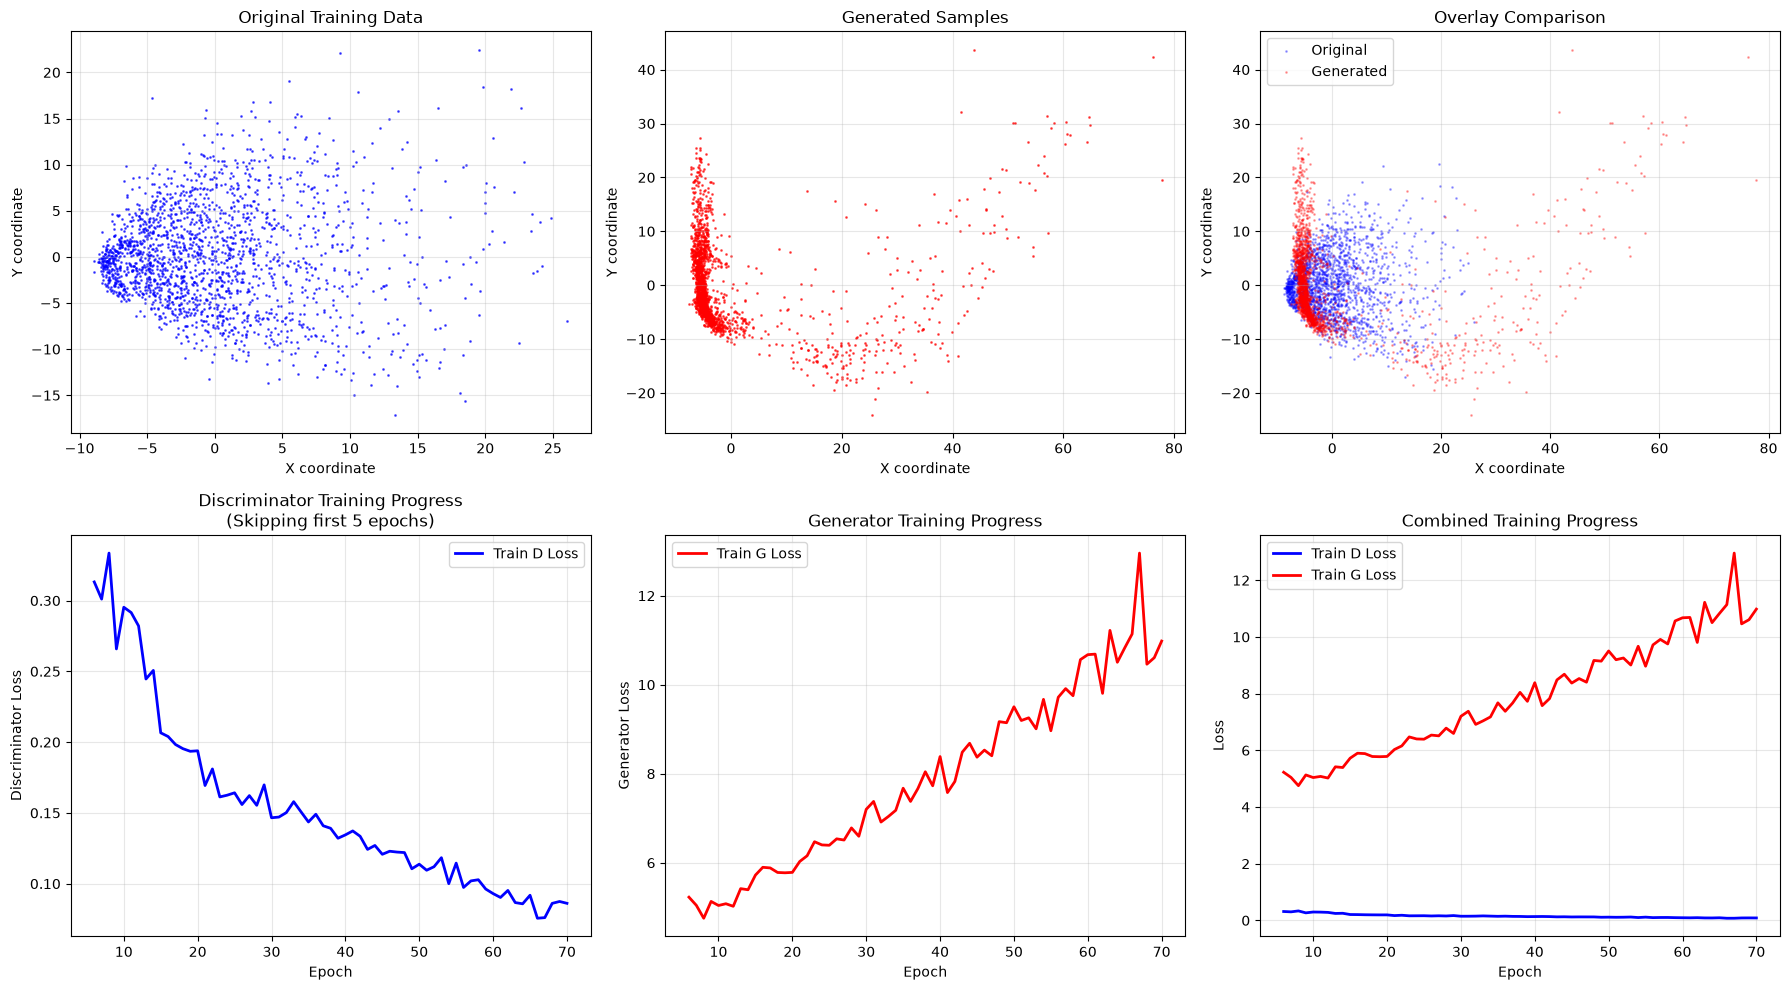

📈 Epoch 70 Summary:
   Train D Loss: 0.0861, Val D Loss: 0.1403
   Train G Loss: 10.9812, Val G Loss: 6.8813

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.093361	G_loss: 8.029604
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.056887	G_loss: 7.756512
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.052843	G_loss: 7.307371
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.037629	G_loss: 7.826577
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.066744	G_loss: 9.107688
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.082415	G_loss: 9.675276
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.040861	G_loss: 13.551642
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.040695	G_loss: 15.869582
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.039064	G_loss: 6.497016
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.041715	G_loss: 7.946433
====> Epoch: 71 Train D_loss: 0.0829, Train G_loss: 10.5317
====> Epoch: 71 Val D_loss: 0.1173, Val G_loss: 5.5500
📈 Epoch 71 Summary:
   Train D Loss: 0.0829, Val D Loss: 0.1173
   Train G Loss: 10

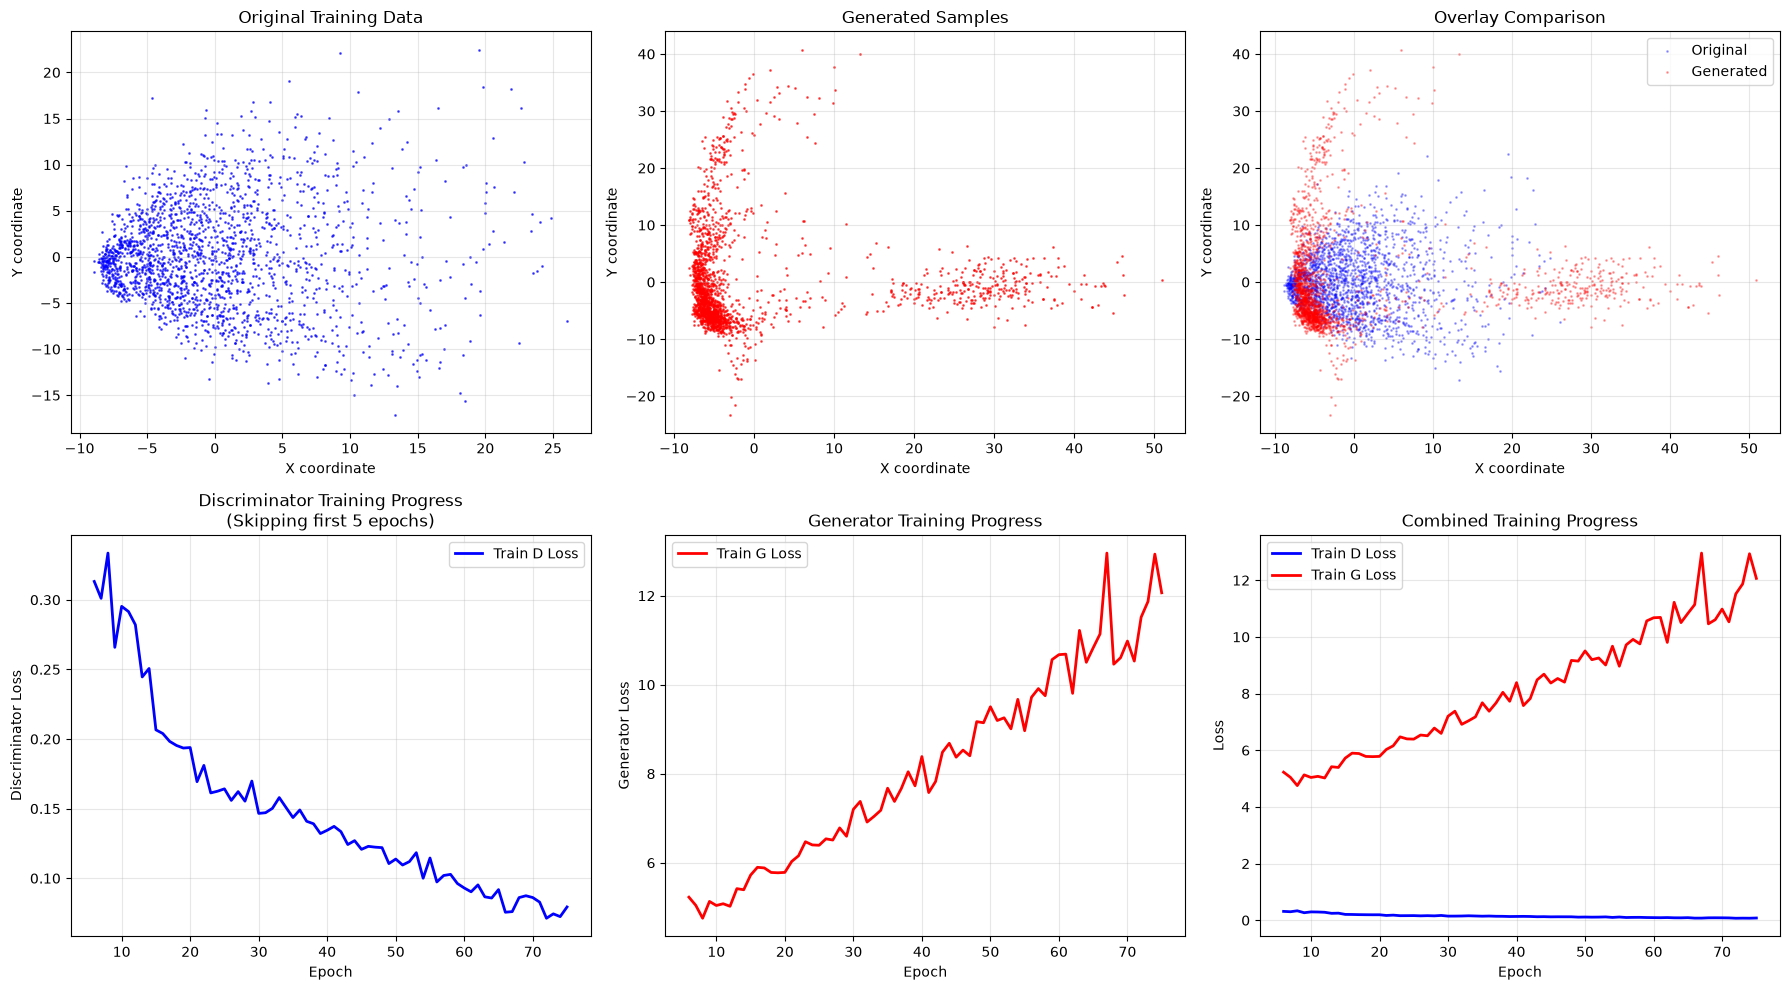

📈 Epoch 75 Summary:
   Train D Loss: 0.0794, Val D Loss: 0.0459
   Train G Loss: 12.0655, Val G Loss: 11.2017

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.019861	G_loss: 9.919077
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.197927	G_loss: 14.751032
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.079160	G_loss: 20.652256
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.019063	G_loss: 14.229383
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.026689	G_loss: 22.437765
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.027494	G_loss: 14.239157
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.039255	G_loss: 11.970558
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.046967	G_loss: 10.658927
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.109029	G_loss: 7.528141
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.017564	G_loss: 9.554628
====> Epoch: 76 Train D_loss: 0.0623, Train G_loss: 12.6032
====> Epoch: 76 Val D_loss: 0.0801, Val G_loss: 12.7569
📈 Epoch 76 Summary:
   Train D Loss: 0.0623, Val D Loss: 0.0801
   Train G L

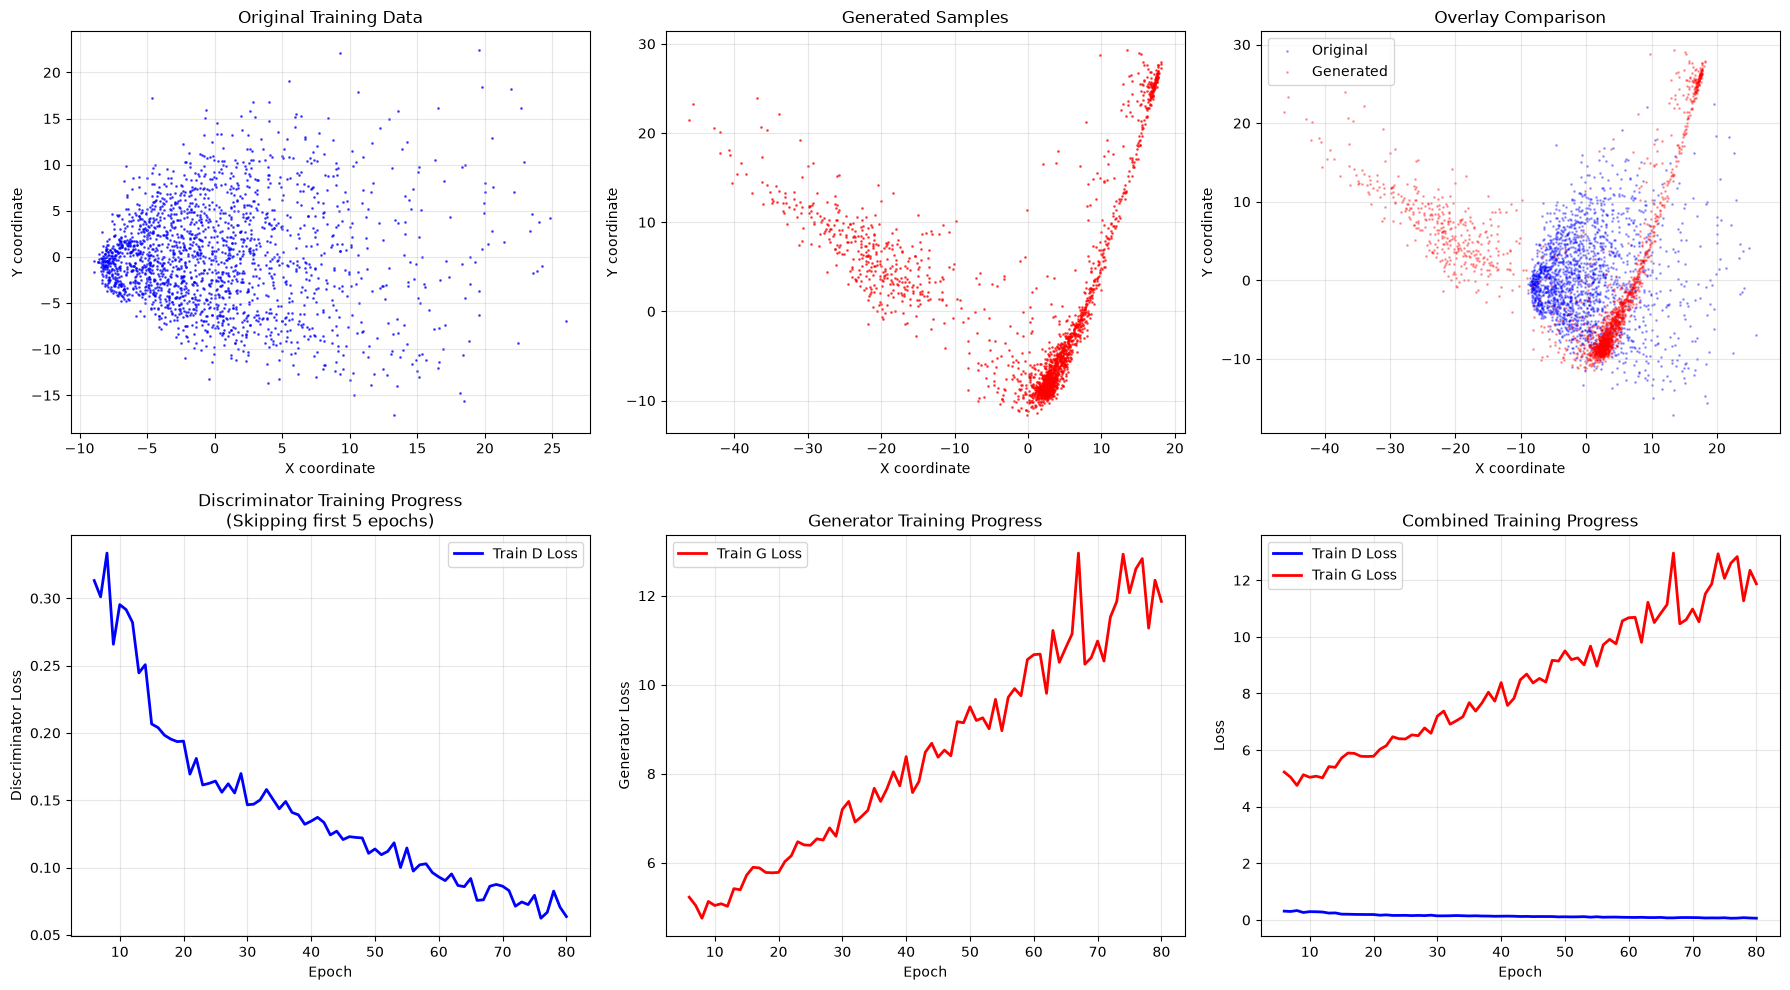

📈 Epoch 80 Summary:
   Train D Loss: 0.0636, Val D Loss: 0.1141
   Train G Loss: 11.8719, Val G Loss: 14.7461

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.038774	G_loss: 16.205170
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.032315	G_loss: 9.599306
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.065075	G_loss: 6.224396
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.030669	G_loss: 10.795164
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.008402	G_loss: 14.109445
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.067280	G_loss: 7.880362
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.143865	G_loss: 10.646576
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.010881	G_loss: 9.390613
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.089561	G_loss: 9.757946
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.069034	G_loss: 7.528667
====> Epoch: 81 Train D_loss: 0.0676, Train G_loss: 11.9375
====> Epoch: 81 Val D_loss: 0.0972, Val G_loss: 7.0434
📈 Epoch 81 Summary:
   Train D Loss: 0.0676, Val D Loss: 0.0972
   Train G Loss:

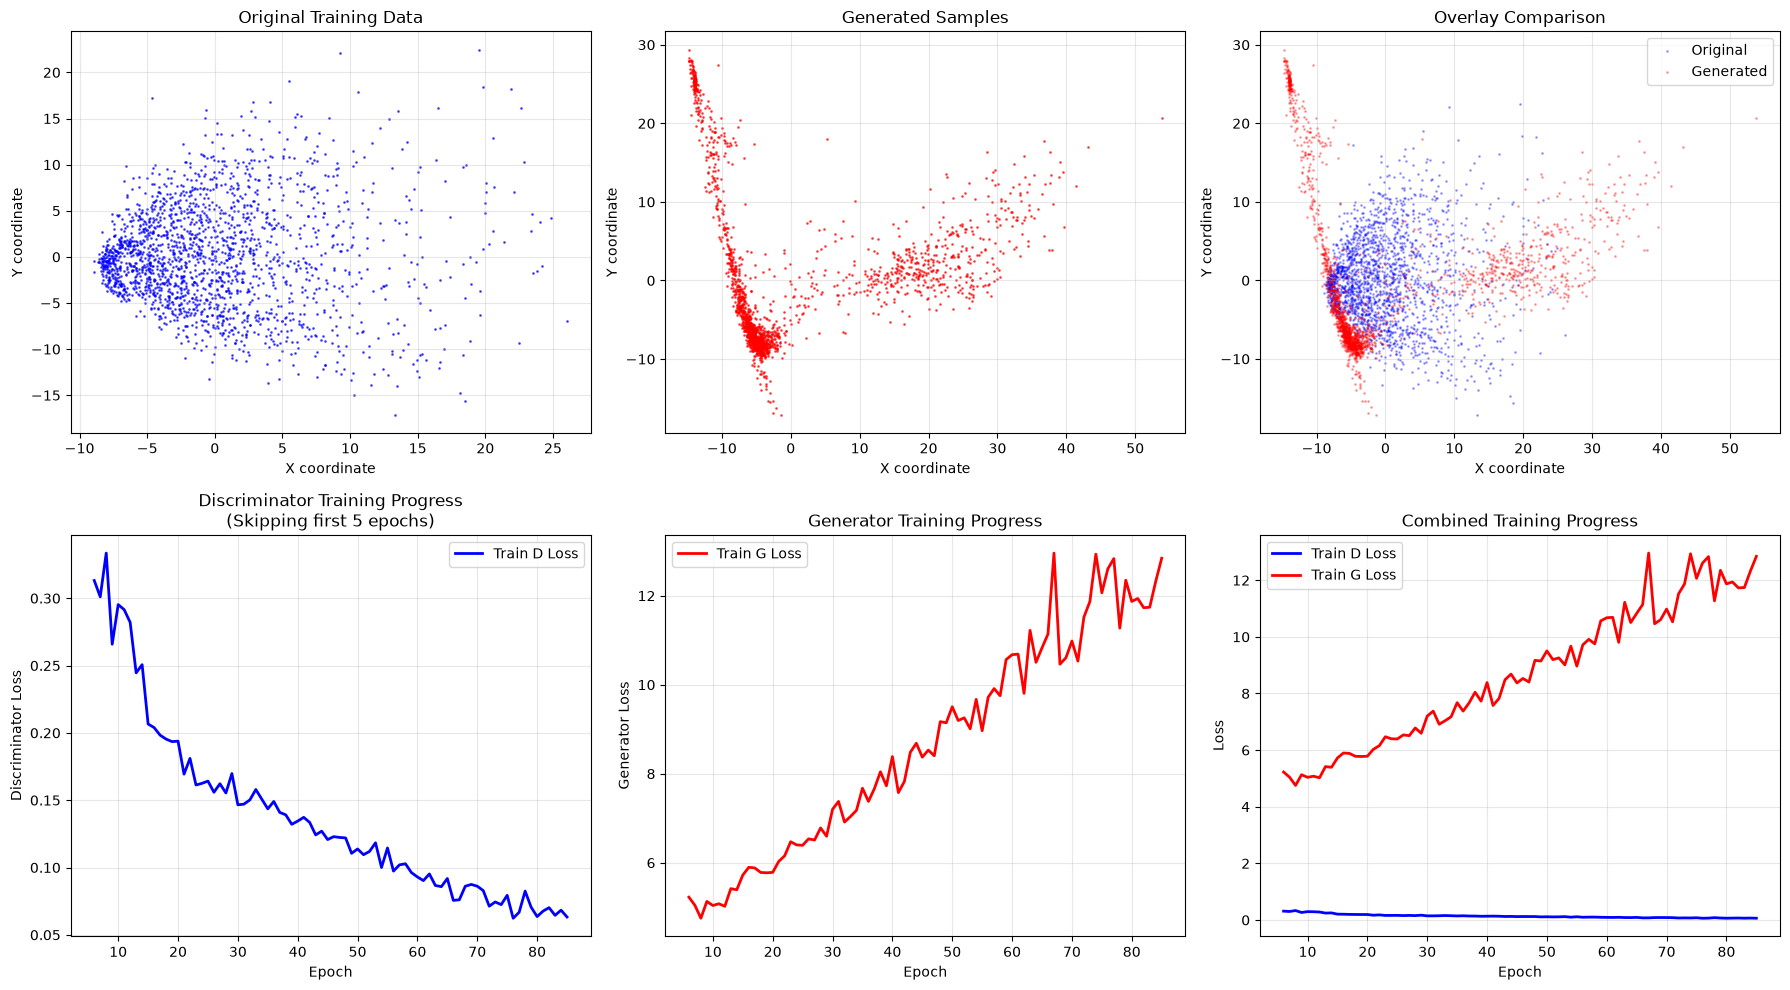

📈 Epoch 85 Summary:
   Train D Loss: 0.0633, Val D Loss: 0.0658
   Train G Loss: 12.8432, Val G Loss: 16.1406

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.055160	G_loss: 17.007671
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.031945	G_loss: 17.530869
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.061390	G_loss: 14.781365
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.023177	G_loss: 12.123865
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.036018	G_loss: 9.222553
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.039734	G_loss: 12.358915
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.025268	G_loss: 7.612494
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.041561	G_loss: 11.916190
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.045985	G_loss: 6.263776
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.035777	G_loss: 8.912910
====> Epoch: 86 Train D_loss: 0.0647, Train G_loss: 11.6607
====> Epoch: 86 Val D_loss: 0.0890, Val G_loss: 6.6632
📈 Epoch 86 Summary:
   Train D Loss: 0.0647, Val D Loss: 0.0890
   Train G Los

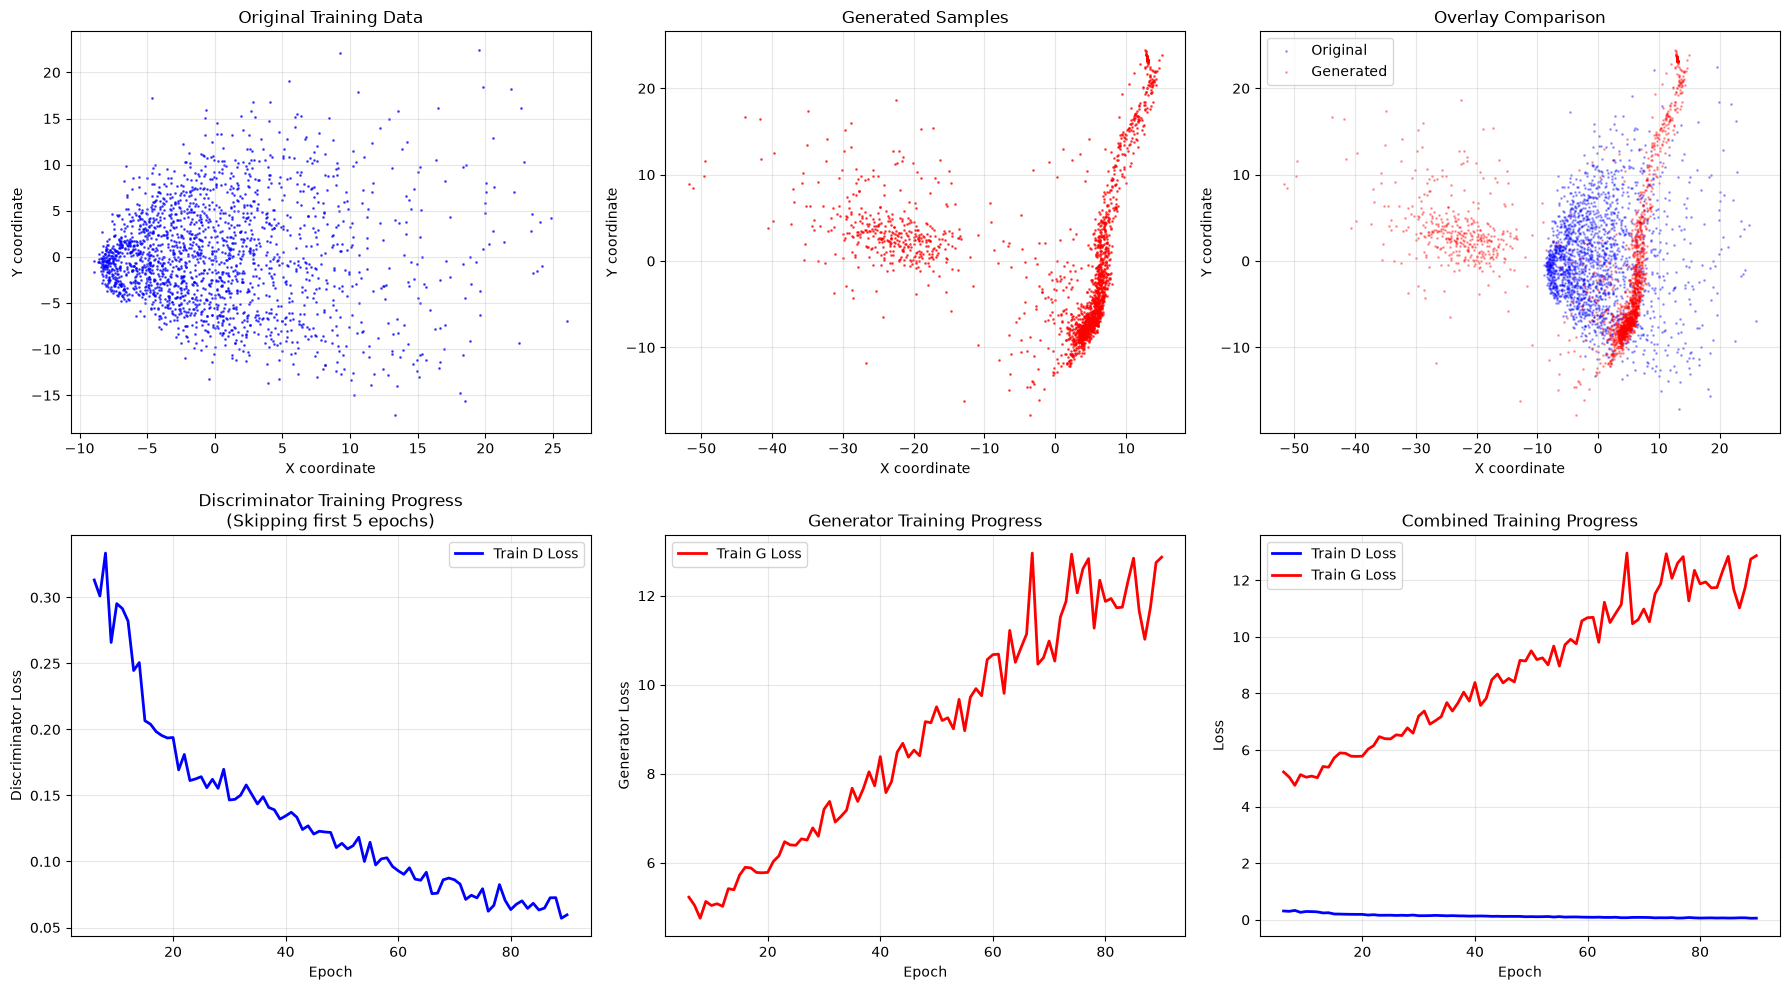

📈 Epoch 90 Summary:
   Train D Loss: 0.0596, Val D Loss: 0.1013
   Train G Loss: 12.8670, Val G Loss: 17.8289

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.019201	G_loss: 18.481590
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.031069	G_loss: 12.076371
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.045808	G_loss: 15.418467
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.024223	G_loss: 14.801435
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.044406	G_loss: 9.792933
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.502257	G_loss: 14.748915
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.048707	G_loss: 10.091565
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.112894	G_loss: 7.358860
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.034301	G_loss: 14.117790
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.038917	G_loss: 21.289316
====> Epoch: 91 Train D_loss: 0.0581, Train G_loss: 12.8955
====> Epoch: 91 Val D_loss: 0.1056, Val G_loss: 19.1373
📈 Epoch 91 Summary:
   Train D Loss: 0.0581, Val D Loss: 0.1056
   Train G 

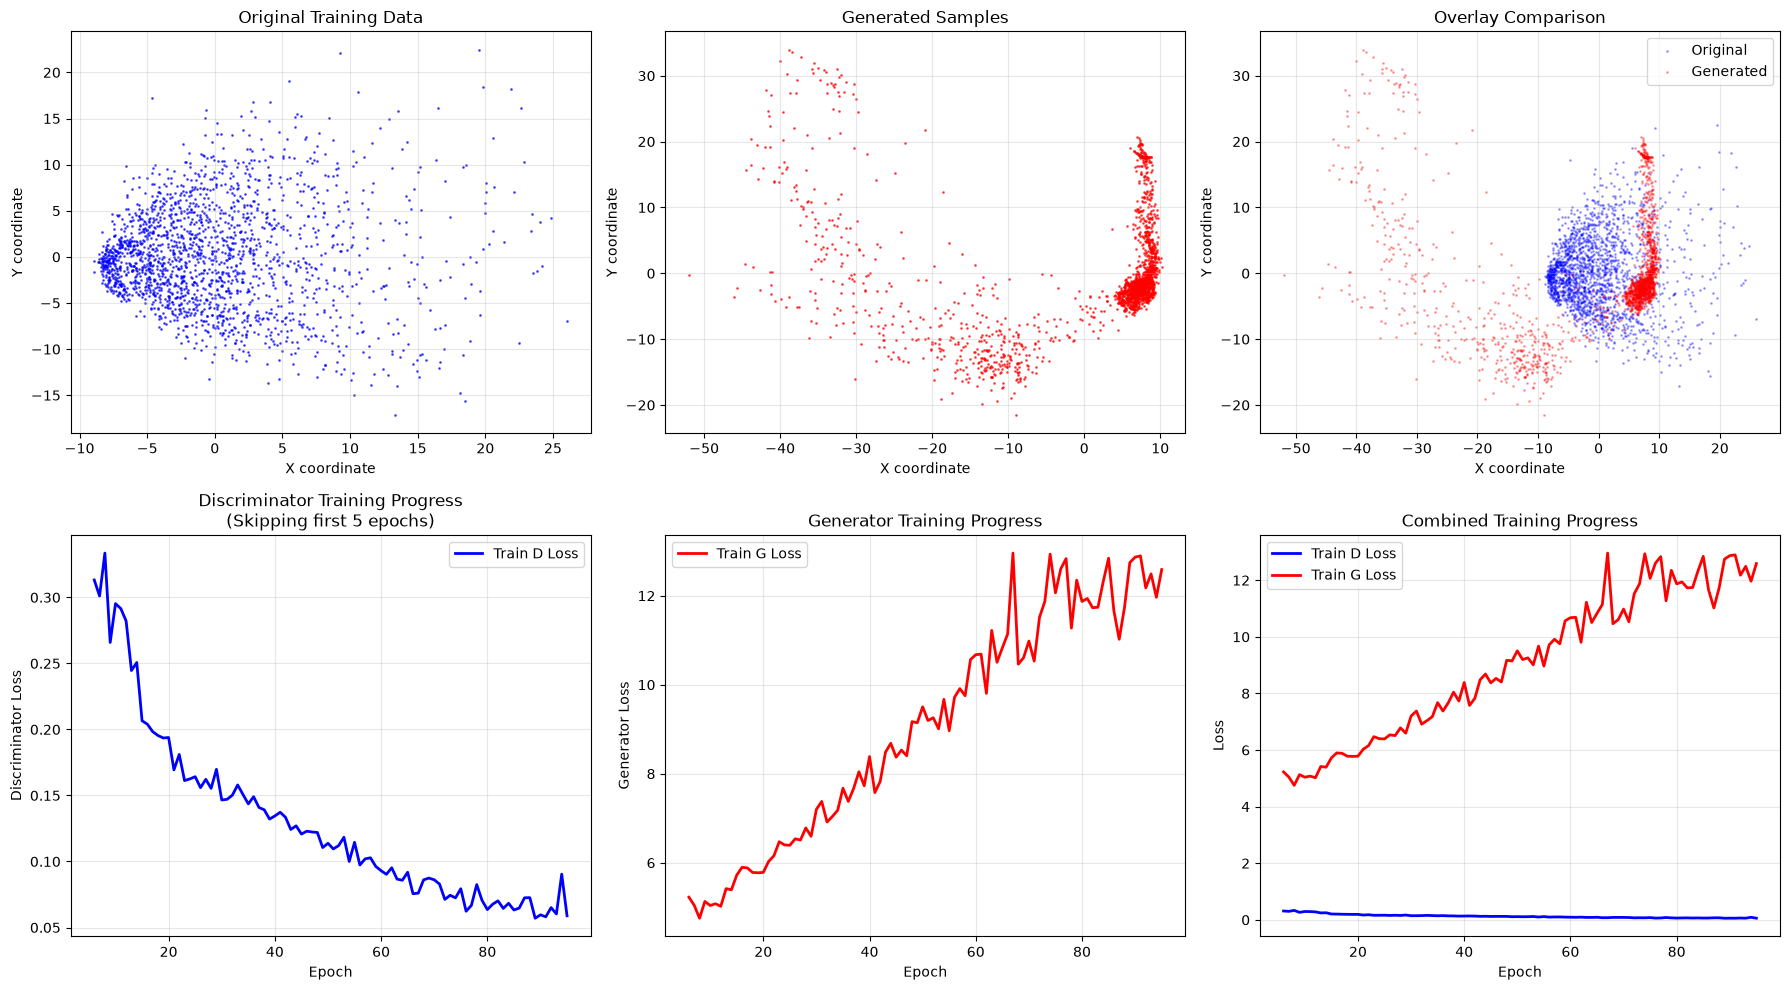

📈 Epoch 95 Summary:
   Train D Loss: 0.0589, Val D Loss: 0.1345
   Train G Loss: 12.5875, Val G Loss: 5.7634

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.108227	G_loss: 6.932268
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.035389	G_loss: 7.563784
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.027610	G_loss: 10.213932
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.056718	G_loss: 13.396825
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.073130	G_loss: 13.089660
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.117863	G_loss: 14.934501
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.065092	G_loss: 10.832498
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.022739	G_loss: 22.290031
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.050062	G_loss: 11.334677
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.021074	G_loss: 11.745895
====> Epoch: 96 Train D_loss: 0.0552, Train G_loss: 12.4808
====> Epoch: 96 Val D_loss: 0.0667, Val G_loss: 11.4579
📈 Epoch 96 Summary:
   Train D Loss: 0.0552, Val D Loss: 0.0667
   Train G L

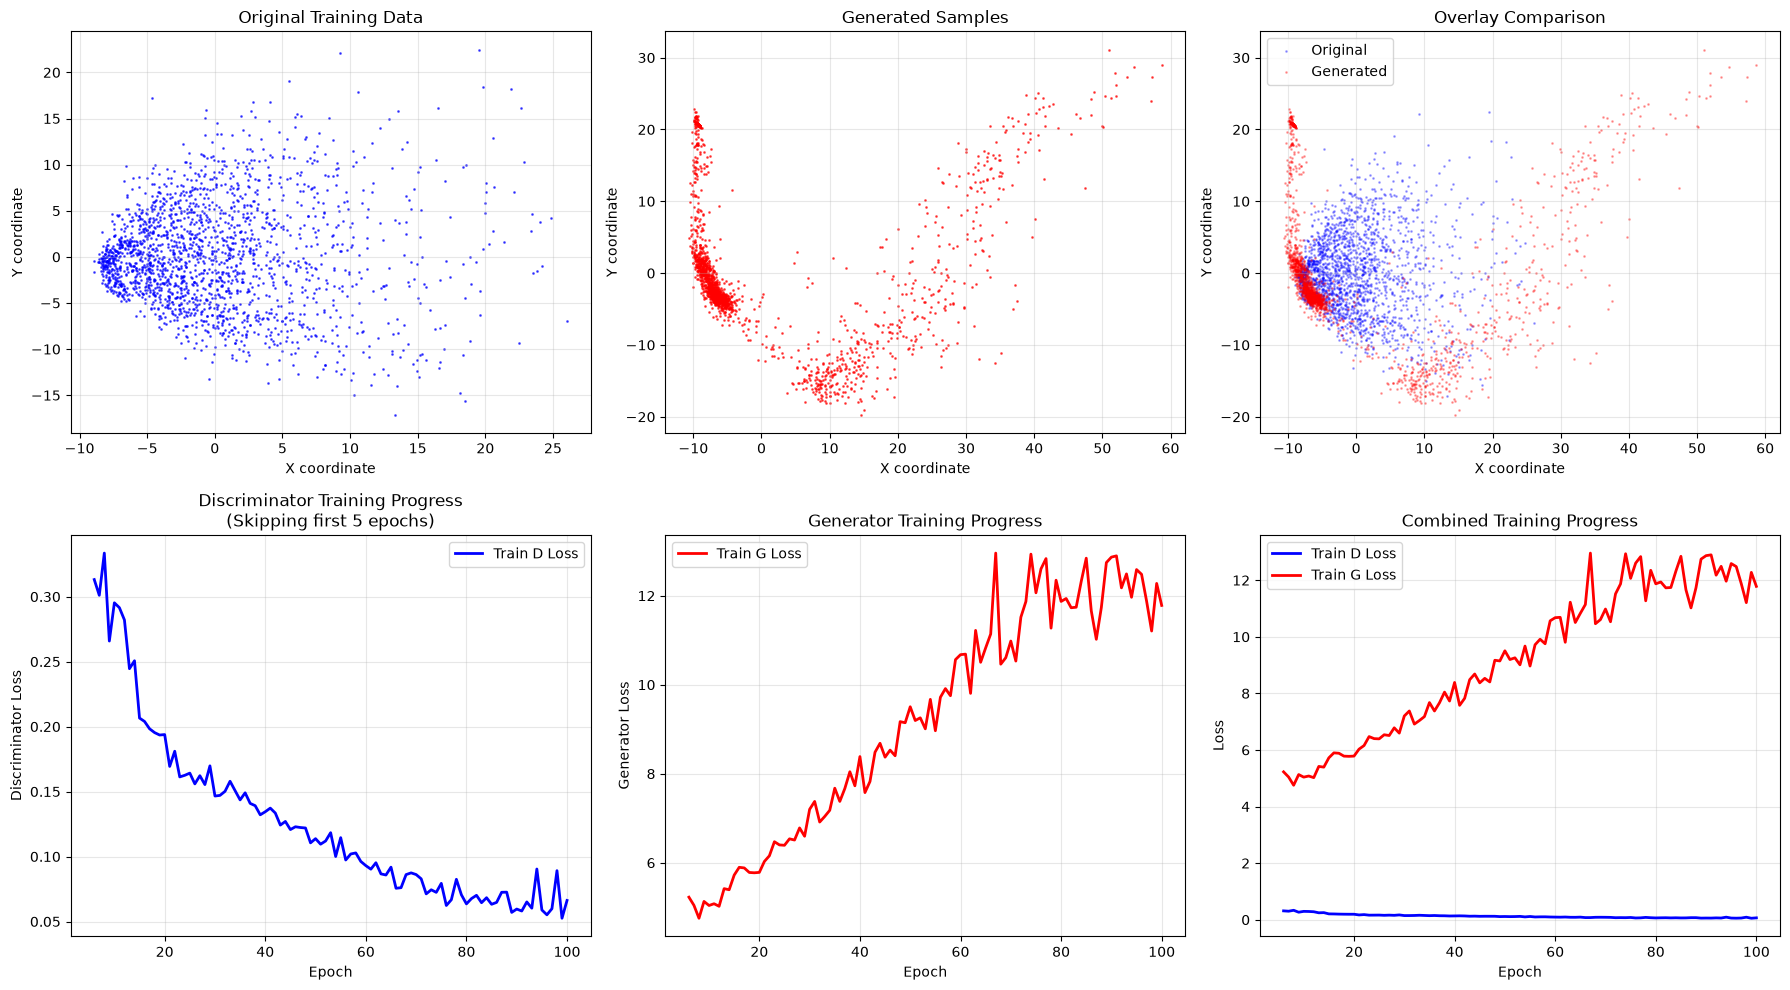

📈 Epoch 100 Summary:
   Train D Loss: 0.0662, Val D Loss: 0.0646
   Train G Loss: 11.7817, Val G Loss: 19.2663

🎉 Training completed!

🎨 Final comprehensive visualization:


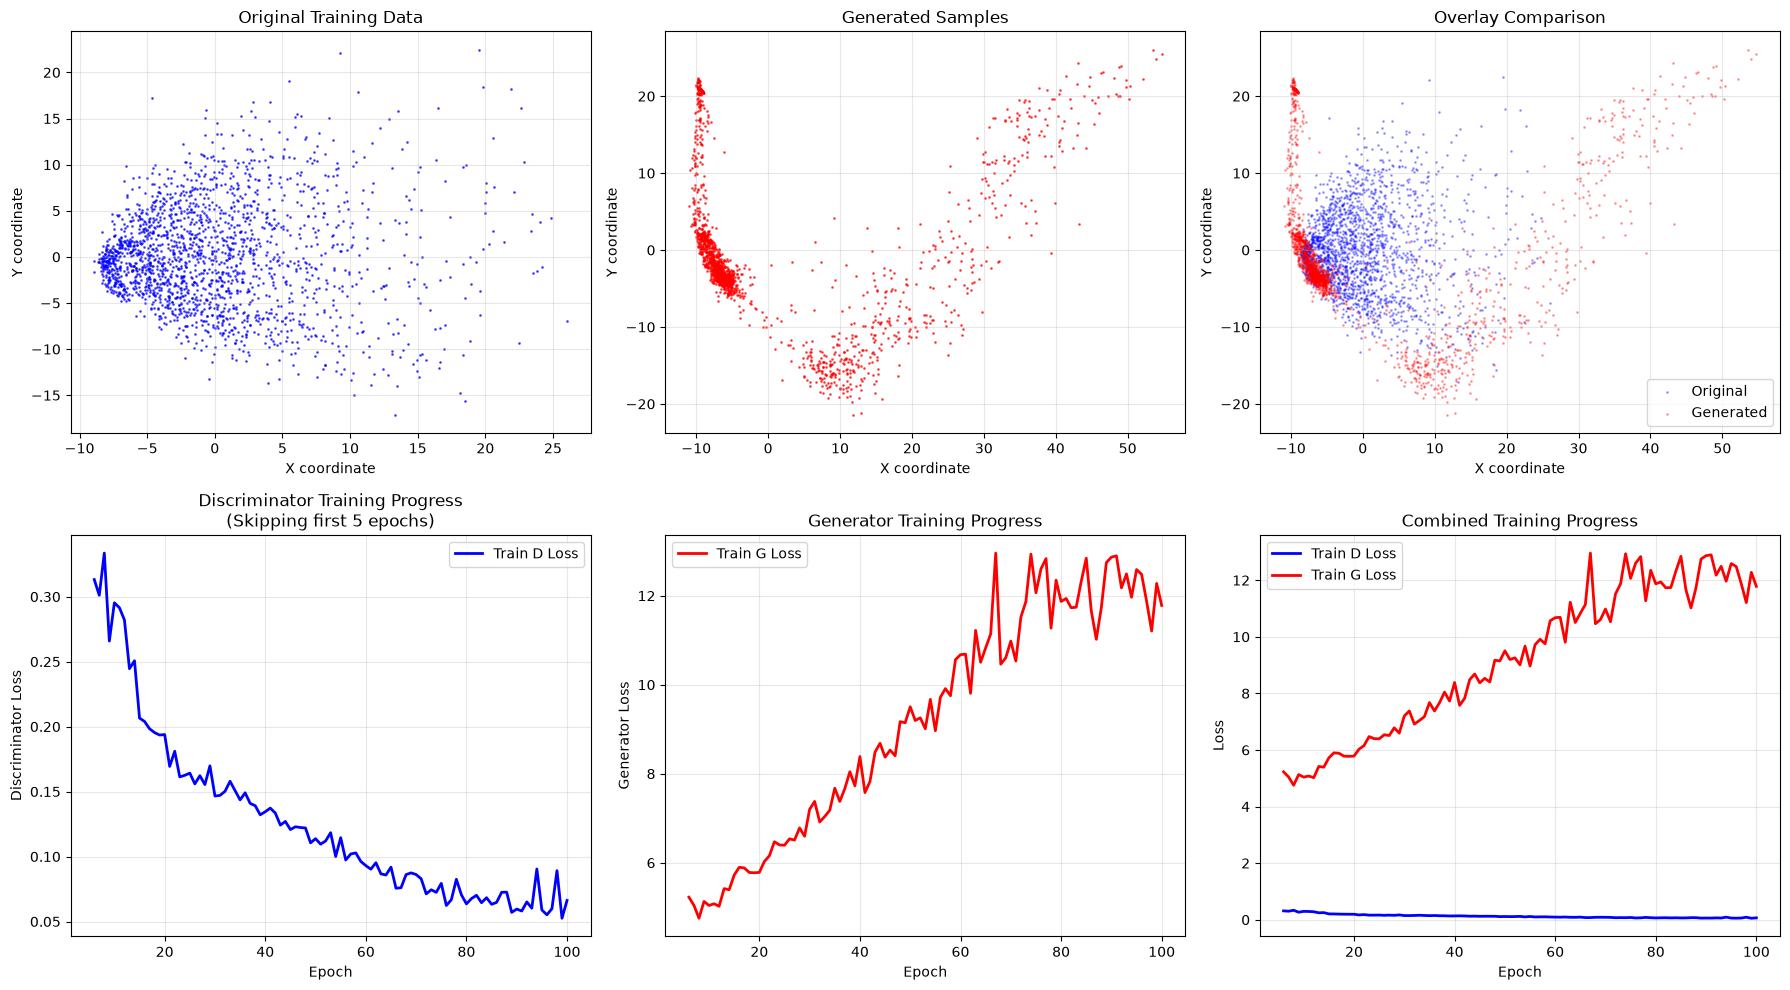

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


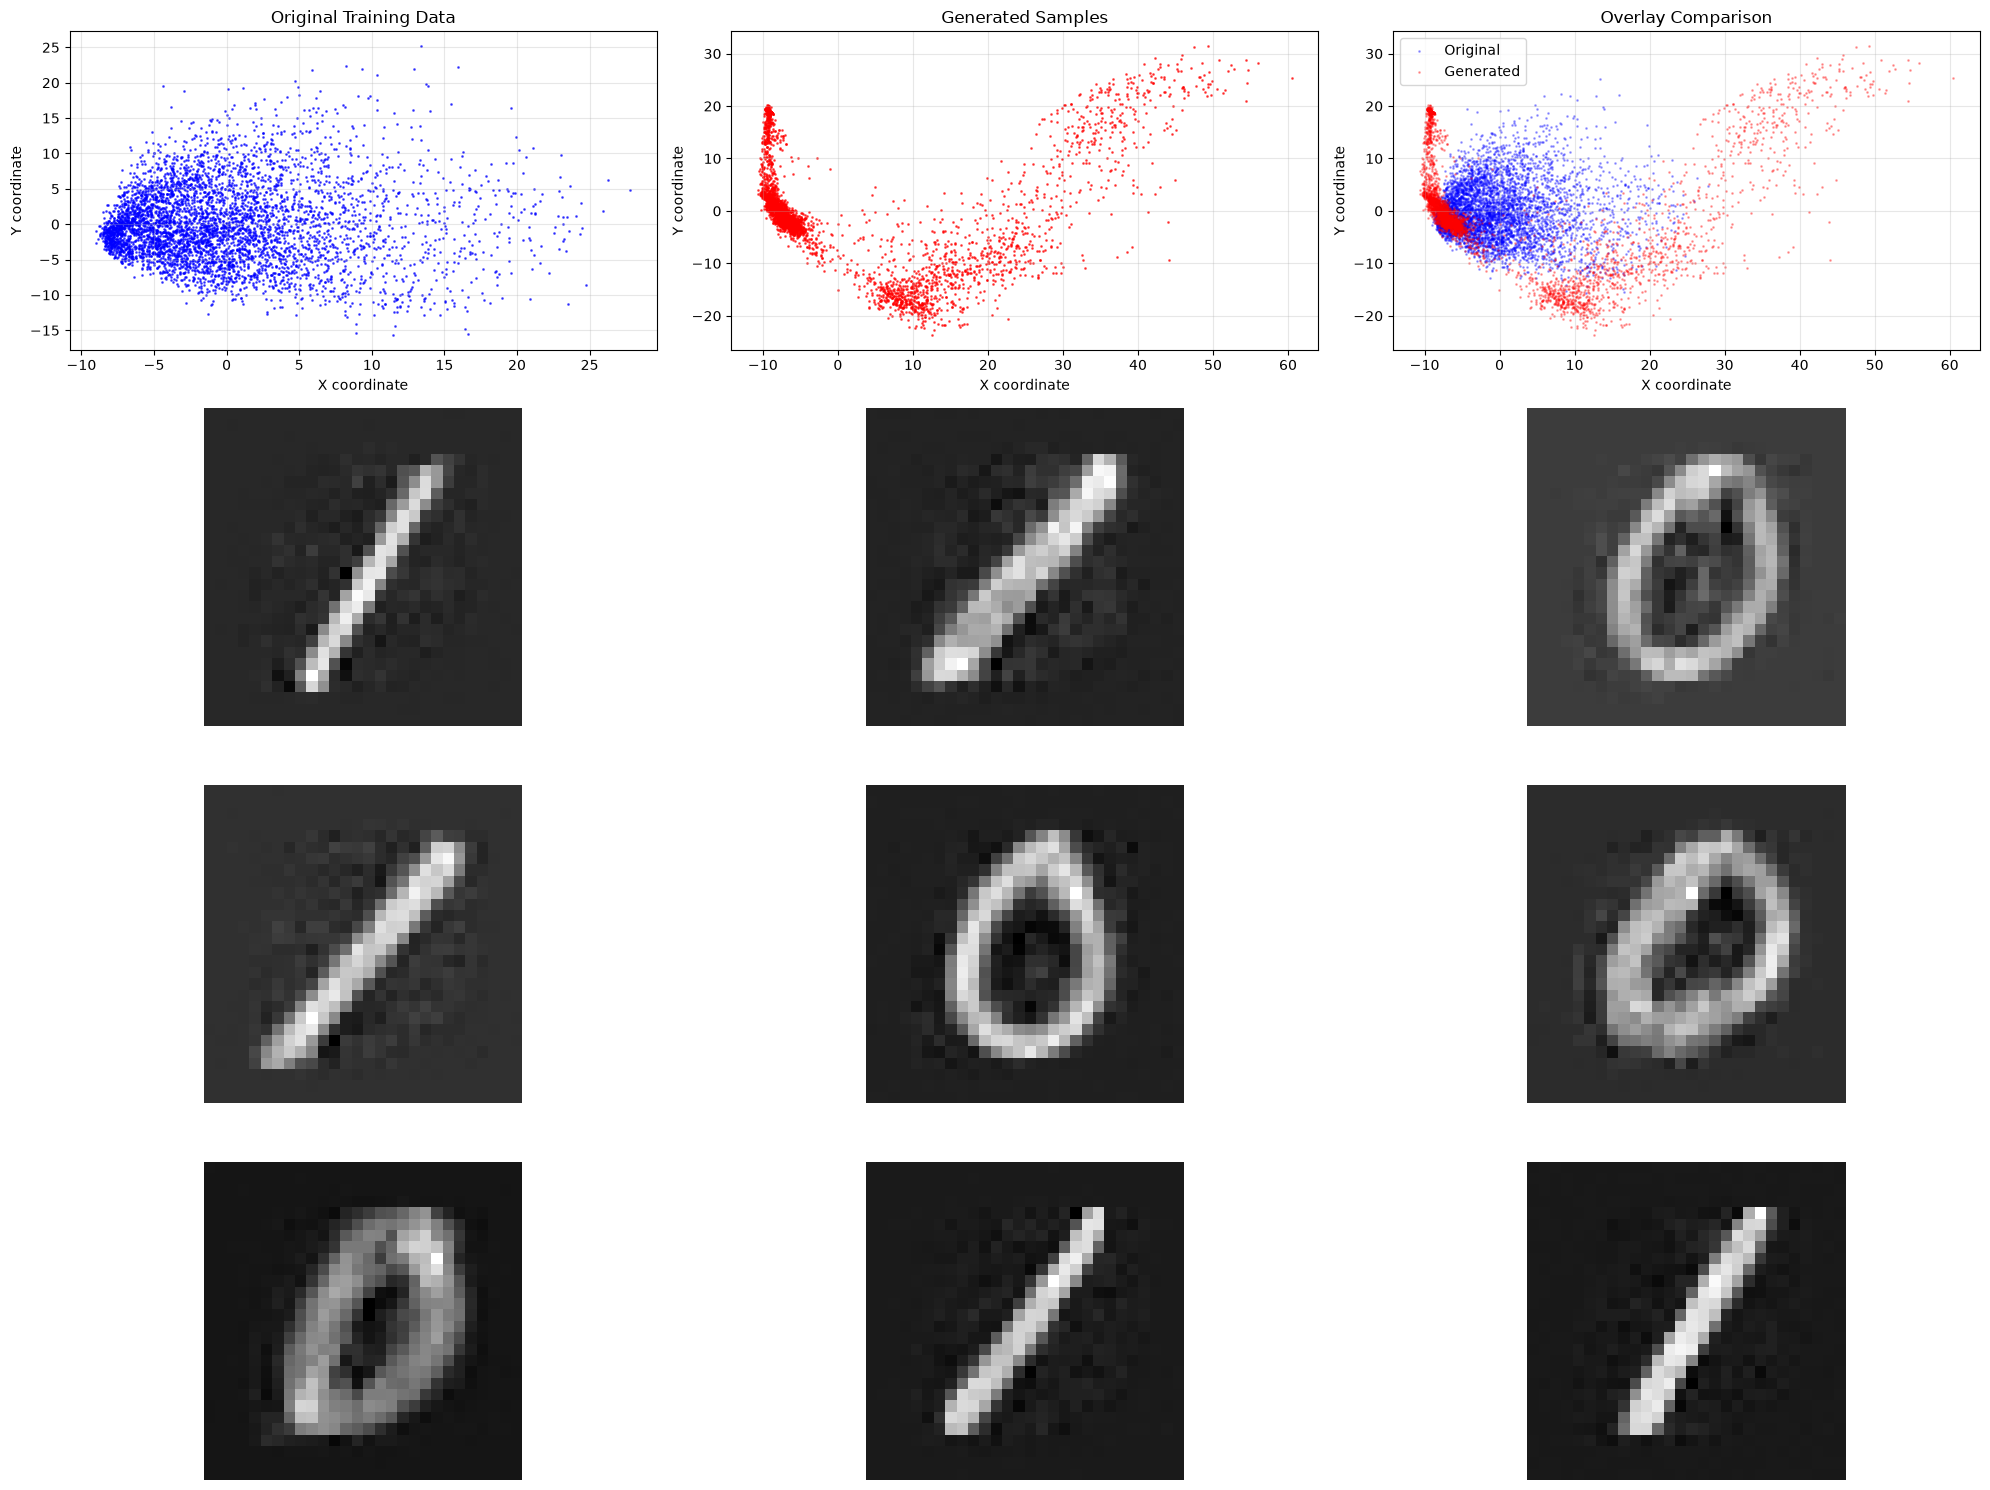

Real data confidence: 0.830
Fake data confidence: 0.000


In [25]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].to(device).float()
    real_batch = real_batch.reshape([100, INPUT_DIM])
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
